# Лабораторная работа 5. Кластеризация категориальных данных. Алгоритм CLOPE

**Данные:** Heart Disease (UCI, Cleveland), 303 пациента, 13 признаков (8 категориальных, 5 количественных).

**План работы (по заданию):**
1. Демо-пример Loginom «Кластеризация транзакций» — воспроизведение на наборе Mushroom.
2. Описание и дескриптивный анализ данных Heart Disease, преобразование к транзакционному виду.
3. Кластеризация методом CLOPE: подбор коэффициента отталкивания *r*, интерпретация, метрики качества, значимость признаков.
4. Кластеризация смешанных данных: мера Гауэра + PAM (k-medoids — аналог k-средних для произвольной меры расстояния), дополнительно k-prototypes.
5. Сравнение решений.

В конце ноутбука — краткий теоретический конспект к вопросам защиты (с формулами).

In [1]:
import itertools
import json
import random
import sys
import warnings
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd
from kmodes.kprototypes import KPrototypes
from scipy import stats
from sklearn import metrics
from sklearn.manifold import MDS

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path(globals().get("__file__", "lr5_clope_heart.py")).resolve().parent
DATA = ROOT / "data"
FIG = ROOT / "figures"
RES = ROOT / "results"
SUMMARY = {}


def setup_environment():
    """Создаёт папки figures/ и results/, задаёт единый стиль рисунков (Times New Roman)."""
    warnings.filterwarnings("ignore")
    FIG.mkdir(exist_ok=True)
    RES.mkdir(exist_ok=True)
    plt.rcParams.update({"font.family": "Times New Roman", "font.size": 12, "axes.titlesize": 13,
                         "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight"})
    sns.set_palette("colorblind")


def savefig(name):
    """Сохраняет текущий рисунок в figures/<name>.png; в ноутбуке показывает его, в скрипте закрывает."""
    plt.savefig(FIG / f"{name}.png")
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close()


def show(obj, digits=None):
    """Выводит таблицу или значение: в ноутбуке через display, в скрипте через print."""
    if digits is not None and hasattr(obj, "round"):
        obj = obj.round(digits)
    if IN_NOTEBOOK:
        from IPython.display import display
        display(obj)
    else:
        print(obj.to_string() if hasattr(obj, "to_string") else obj)
        print()

setup_environment()

**Что делает ячейка.** Подключает библиотеки и задаёт общие настройки. Весь код работы находится в одном файле `lr5_clope_heart.py` и идёт в порядке пунктов задания. В ноутбуке тот же код разбит на ячейки: функции определены в той ячейке, где они впервые нужны, а под каждой ячейкой описано, что она делает.

| Пункт задания | Основные функции |
|---|---|
| 1. Демо-пример Loginom | `Cluster`, `delta_add`, `profit`, `clope`, `cluster_stats`, `external_metrics`, `demo_loginom` |
| 2. Описание датасета | `load_heart`, `describe_dataset` |
| 3. Дескриптивный анализ | `descriptive_numeric`, `categorical_frequencies`, `discretize`, `cramers_v`, `association_analysis` |
| 4. Преобразование данных | `to_transactions`, `to_long_table`, `transform_data` |
| 5. CLOPE | `hamming_matrix`, `silhouette`, `stability`, `merge_small_clusters`, `clope_grid_search`, `choose_r`, `clope_final`, `item_profile`, `feature_significance` |
| 6. Гауэр + PAM | `gower_matrix`, `gower_contributions`, `pam`, `pam_grid_search`, `pam_profiles`, `bootstrap_stability`, `kprototypes_check` |
| 7. Сравнение | `compare_solutions`, `plot_comparison`, `save_results` |

Константа `IN_NOTEBOOK` определяет, где выполняется код. В ноутбуке рисунки и таблицы выводятся прямо в ячейках, а при запуске `python lr5_clope_heart.py` таблицы печатаются в консоль, рисунки только сохраняются. `savefig` записывает рисунки в `figures/`, `show` выводит таблицы, словарь `SUMMARY` собирает ключевые числа для отчёта.

## 1. Демо-пример Loginom «Кластеризация транзакций»

В демо-примере Loginom кластеризуются 8124 гриба (22 характеристики + класс «съедобный/ядовитый»). Сценарий:
1. **Импорт** таблицы;
2. **Добавление ID** (`RowNum() + 1`) — уникальный номер записи = номер транзакции;
3. **Свёртка столбцов** — таблица «объект × признак» превращается в длинную таблицу (ID, Метка, Значение);
4. **Калькулятор** — элемент `Concat(display_names, " — ", values)`, т.е. «признак — значение»;
5. **Кластеризация транзакций** (CLOPE): поле ID → «Транзакция», поле «Свойство» → «Элемент», коэффициент отталкивания по умолчанию *r* = 2,6;
6. **Таблица** «Параметры кластеров» (N, W, S) и **Куб** (номер кластера × класс) — проверка числа «грязных» кластеров, где есть и съедобные, и ядовитые грибы.

Ниже то же самое воспроизведено собственной реализацией CLOPE (порядок транзакций — исходный, как в Loginom).

In [2]:
class Cluster:
    """Кластер CLOPE: число транзакций N, площадь S, гистограмма элементов Occ и ширина W."""

    __slots__ = ("n", "s", "occ")

    def __init__(self):
        """Создаёт пустой кластер (N = 0, S = 0, Occ = {})."""
        self.n = 0
        self.s = 0
        self.occ = {}

    @property
    def w(self):
        """Ширина кластера W — число различных элементов."""
        return len(self.occ)

    def add(self, t):
        """Добавляет транзакцию t, обновляя N, S и гистограмму Occ."""
        self.n += 1
        self.s += len(t)
        for i in t:
            self.occ[i] = self.occ.get(i, 0) + 1

    def remove(self, t):
        """Удаляет транзакцию t из кластера, обновляя N, S и Occ."""
        self.n -= 1
        self.s -= len(t)
        for i in t:
            c = self.occ[i] - 1
            if c:
                self.occ[i] = c
            else:
                del self.occ[i]


def delta_add(cl, t, r):
    """Приращение числителя Profit при добавлении транзакции t в кластер cl.

    DeltaAdd = S_new * (N + 1) / W_new ** r - S * N / W ** r,
    где S_new = S + |t|, W_new = W + число элементов t, отсутствующих в cl.
    Для пустого кластера DeltaAdd = |t| / |t| ** r.
    """
    s_new = cl.s + len(t)
    w_new = cl.w + sum(1 for i in t if i not in cl.occ)
    if cl.n == 0:
        return s_new / (w_new ** r)
    return s_new * (cl.n + 1) / (w_new ** r) - cl.s * cl.n / (cl.w ** r)


def _best_cluster(clusters, t, r, max_clusters):
    """Индекс кластера с максимальным DeltaAdd или None, если выгоднее открыть новый кластер."""
    best_i, best_d = None, float("-inf")
    for idx, cl in enumerate(clusters):
        if cl.n == 0:
            continue
        d = delta_add(cl, t, r)
        if d > best_d:
            best_i, best_d = idx, d
    n_active = sum(1 for c in clusters if c.n > 0)
    if max_clusters is None or n_active < max_clusters:
        if len(t) / (len(set(t)) ** r) > best_d:
            return None
    return best_i


def profit(clusters, r):
    """Глобальный критерий Profit(C, r) = sum(S_i * N_i / W_i ** r) / sum(N_i)."""
    active = [c for c in clusters if c.n > 0]
    num = sum(c.s * c.n / (c.w ** r) for c in active)
    return num / sum(c.n for c in active)


def _relabel_by_size(labels):
    """Перенумеровывает кластеры 0..k-1 по убыванию размера."""
    sizes = {}
    for lab in labels:
        sizes[lab] = sizes.get(lab, 0) + 1
    ranking = sorted(sizes, key=lambda k: -sizes[k])
    remap = {old: new for new, old in enumerate(ranking)}
    return [remap[lab] for lab in labels]


def clope(transactions, r=2.6, max_iter=50, max_clusters=None, seed=None):
    """Кластеризация транзакций алгоритмом CLOPE (Yang, Guan, You, 2002).

    Фаза 1 (инициализация): транзакции просматриваются по очереди, каждая
    помещается в кластер с максимальным DeltaAdd (или в новый кластер).
    Фаза 2 (итерации): каждая транзакция извлекается из своего кластера и
    повторно размещается по максимуму DeltaAdd; проходы повторяются, пока
    происходят перемещения (или до max_iter).

    Параметры: transactions — список транзакций (списков элементов-строк);
    r — коэффициент отталкивания; max_clusters — ограничение числа кластеров
    (как в Loginom); seed — случайный порядок просмотра транзакций
    (None — исходный порядок).

    Возвращает (labels, profit, history, n_iter): номера кластеров (0 — самый
    крупный), итоговый Profit, Profit после инициализации и каждой итерации,
    число итераций фазы 2.
    """
    order = list(range(len(transactions)))
    if seed is not None:
        random.Random(seed).shuffle(order)
    clusters = []
    labels = [None] * len(transactions)

    for j in order:
        t = transactions[j]
        b = _best_cluster(clusters, t, r, max_clusters)
        if b is None:
            clusters.append(Cluster())
            b = len(clusters) - 1
        clusters[b].add(t)
        labels[j] = b
    history = [profit(clusters, r)]

    n_iter = 0
    for _ in range(max_iter):
        moved = False
        n_iter += 1
        for j in order:
            t = transactions[j]
            cur = labels[j]
            clusters[cur].remove(t)
            b = _best_cluster(clusters, t, r, max_clusters)
            if b is None:
                if clusters[cur].n == 0:
                    b = cur
                else:
                    clusters.append(Cluster())
                    b = len(clusters) - 1
            clusters[b].add(t)
            labels[j] = b
            if b != cur:
                moved = True
        history.append(profit(clusters, r))
        if not moved:
            break

    return _relabel_by_size(labels), history[-1], history, n_iter


def build_clusters(transactions, labels):
    """Восстанавливает объекты Cluster по транзакциям и меткам кластеров."""
    clusters = {}
    for t, lab in zip(transactions, labels):
        clusters.setdefault(lab, Cluster()).add(t)
    return clusters


def cluster_stats(transactions, labels):
    """Параметры кластеров, как на выходе «Параметры кластеров» Loginom: N, W, S, H = S / W, G = S / W ** 2."""
    out = []
    clusters = build_clusters(transactions, labels)
    for lab in sorted(clusters):
        c = clusters[lab]
        out.append({"cluster": lab, "N": c.n, "W": c.w, "S": c.s,
                    "H": c.s / c.w, "G": c.s / c.w ** 2})
    return out


def purity(y_true, labels):
    """Чистота: доля объектов, принадлежащих преобладающему классу своего кластера."""
    ct = pd.crosstab(np.asarray(labels), np.asarray(y_true))
    return ct.max(axis=1).sum() / ct.values.sum()


def external_metrics(y_true, labels):
    """Внешние метрики относительно эталона: ARI, NMI, однородность, полнота, V-мера, Purity."""
    h, c, v = metrics.homogeneity_completeness_v_measure(y_true, labels)
    return {"ARI": metrics.adjusted_rand_score(y_true, labels),
            "NMI": metrics.normalized_mutual_info_score(y_true, labels),
            "Homogeneity": h, "Completeness": c, "V-measure": v,
            "Purity": purity(y_true, labels)}


def load_mushroom(path):
    """Загружает Mushroom (agaricus-lepiota.data): 8124 гриба, класс и 22 признака."""
    cols = ["class"] + [f"a{i}" for i in range(1, 23)]
    return pd.read_csv(path, header=None, names=cols)


def mushroom_transactions(df, with_class=True):
    """Транзакции демо-примера Loginom из элементов «признак=значение».

    Аналог узлов «Добавление ID» → «Свёртка столбцов» → «Калькулятор».
    Значение «?» считается обычной категорией; класс по умолчанию входит в транзакцию.
    """
    use = list(df.columns) if with_class else list(df.columns[1:])
    return [[f"{c}={v}" for c, v in zip(use, row)] for row in df[use].itertuples(index=False)]


def demo_loginom():
    """Пункт 1: воспроизводит демо-пример Loginom — CLOPE с r = 2,6 на наборе Mushroom.

    Решение строится дважды: с классом в транзакциях (как в Loginom) и без класса.
    «Грязный» кластер содержит и съедобные, и ядовитые грибы.
    """
    mush = load_mushroom(DATA / "agaricus-lepiota.data")
    tr = mushroom_transactions(mush, with_class=True)
    lab, prof, hist, it = clope(tr, r=2.6)
    st = pd.DataFrame(cluster_stats(tr, lab)).sort_values("S", ascending=False)
    ct = pd.crosstab(pd.Series(lab, name="cluster"), mush["class"])
    dirty = int(((ct > 0).sum(axis=1) == 2).sum())

    tr_nc = mushroom_transactions(mush, with_class=False)
    lab_nc, _, _, _ = clope(tr_nc, r=2.6)
    ct_nc = pd.crosstab(pd.Series(lab_nc, name="cluster"), mush["class"])
    dirty_nc = int(((ct_nc > 0).sum(axis=1) == 2).sum())
    m_nc = external_metrics(mush["class"], lab_nc)

    n_items = len({i for t in tr for i in t})
    print(f"Транзакций: {len(tr)}, уникальных элементов: {n_items}")
    print(f"С классом в транзакции: кластеров {len(ct)}, «грязных» {dirty}, Profit = {prof:.4f}, итераций {it}")
    print(f"Без класса: кластеров {len(ct_nc)}, «грязных» {dirty_nc}, Purity = {m_nc['Purity']:.4f}, ARI = {m_nc['ARI']:.4f}")
    return {"stats": st, "ct": ct, "ct_nc": ct_nc, "n_tr": len(tr), "n_items": n_items, "dirty": dirty,
            "profit": prof, "iter": it, "dirty_nc": dirty_nc, "m_nc": m_nc}

demo = demo_loginom()
show(demo["stats"].head(5))

Транзакций: 8124, уникальных элементов: 119
С классом в транзакции: кластеров 24, «грязных» 0, Profit = 2.1984, итераций 2
Без класса: кластеров 23, «грязных» 1, Purity = 0.9961, ARI = 0.2354


,cluster,N,W,S,H,G
0,0,1728,35,39744,1135.542857,32.444082
2,2,1296,35,29808,851.657143,24.333061
1,1,1296,35,29808,851.657143,24.333061
3,3,768,34,17664,519.529412,15.280277
4,4,512,33,11776,356.848485,10.813590


**Функции и классы ячейки:**
- `Cluster` — кластер CLOPE: число транзакций N, площадь S, гистограмма элементов Occ и ширина W.
- `delta_add` — приращение числителя Profit при добавлении транзакции t в кластер cl.
- `_best_cluster` — индекс кластера с максимальным DeltaAdd или None, если выгоднее открыть новый кластер.
- `profit` — глобальный критерий Profit(C, r) = sum(S_i * N_i / W_i ** r) / sum(N_i).
- `_relabel_by_size` — перенумеровывает кластеры 0..k-1 по убыванию размера.
- `clope` — кластеризация транзакций алгоритмом CLOPE (Yang, Guan, You, 2002).
- `build_clusters` — восстанавливает объекты Cluster по транзакциям и меткам кластеров.
- `cluster_stats` — параметры кластеров, как на выходе «Параметры кластеров» Loginom: N, W, S, H = S / W, G = S / W ** 2.
- `purity` — чистота: доля объектов, принадлежащих преобладающему классу своего кластера.
- `external_metrics` — внешние метрики относительно эталона: ARI, NMI, однородность, полнота, V-мера, Purity.
- `load_mushroom` — загружает Mushroom (agaricus-lepiota.data): 8124 гриба, класс и 22 признака.
- `mushroom_transactions` — транзакции демо-примера Loginom из элементов «признак=значение».
- `demo_loginom` — пункт 1: воспроизводит демо-пример Loginom — CLOPE с r = 2,6 на наборе Mushroom.

In [3]:
def loginom_comparison(demo):
    """Сопоставляет пять самых мощных кластеров с таблицей «Параметры кластеров» из демо-примера Loginom."""
    loginom_ref = pd.DataFrame({"N": [1728, 1296, 1296, 768, 512], "W": [35, 35, 35, 34, 33],
                                "S": [39744, 29808, 29808, 17664, 11776]})
    own = demo["stats"].head(5)[["N", "W", "S"]].reset_index(drop=True).add_suffix(" (Python)")
    tab = pd.concat([loginom_ref.add_suffix(" (Loginom)"), own], axis=1)
    tab.insert(0, "Ранг по S", range(1, 6))
    tab.to_csv(RES / "demo_mushroom.csv", index=False)
    ct_nc = demo["ct_nc"]
    dirty_list = ct_nc[(ct_nc > 0).sum(axis=1) == 2]
    SUMMARY["demo"] = {"n_tr": demo["n_tr"], "n_items": demo["n_items"], "k": int(len(demo["ct"])),
                       "dirty": demo["dirty"], "profit": demo["profit"], "iter": demo["iter"],
                       "k_nc": int(len(ct_nc)), "dirty_nc": demo["dirty_nc"], "purity_nc": demo["m_nc"]["Purity"],
                       "ari_nc": demo["m_nc"]["ARI"], "dirty_nc_sizes": dirty_list.to_dict("index")}
    return tab

demo_tab = loginom_comparison(demo)
show(demo_tab)

,Ранг по S,N (Loginom),W (Loginom),S (Loginom),N (Python),W (Python),S (Python)
0,1,1728,35,39744,1728,35,39744
1,2,1296,35,29808,1296,35,29808
2,3,1296,35,29808,1296,35,29808
3,4,768,34,17664,768,34,17664
4,5,512,33,11776,512,33,11776


**Функции и классы ячейки:**
- `loginom_comparison` — сопоставляет пять самых мощных кластеров с таблицей «Параметры кластеров» из демо-примера Loginom.

**Что делают ячейки.** Набор Mushroom переводится в транзакции вида `признак=значение` (функция `mushroom_transactions`, аналог узлов «Добавление ID → Свёртка столбцов → Калькулятор»), затем запускается `clope` с *r* = 2,6. Функция `cluster_stats` возвращает те же характеристики, что порт «Параметры кластеров» Loginom:

- $N(C)$ — число транзакций в кластере;
- $W(C)$ — ширина, число различных элементов;
- $S(C)=\sum_i Occ(i,C)$ — площадь (мощность) кластера;
- $H(C)=S(C)/W(C)$ — средняя высота гистограммы.

Пять самых «мощных» кластеров полностью совпадают с таблицей из демо-примера Loginom по N, W и S (1728 / 1296 / 1296 / 768 / 512 транзакций), что подтверждает корректность реализации.

Кросс-таблица «кластер × класс» — аналог визуализатора «Куб»: число «грязных» кластеров (содержащих оба класса) — критерий качества демо-примера. Если исключить класс из транзакций (честная постановка без учителя), CLOPE всё равно почти идеально разделяет грибы (высокая Purity): данные Mushroom имеют сильную транзакционную структуру — у разных групп грибов разные наборы признаков, ширина *W* кластеров мала.

### Иллюстрация критерия CLOPE (пример из статьи Loginom)

Транзакции $\{ab, abc, acd, de, def\}$. Сравниваются разбиения (1) $\{\{ab, abc, acd\}, \{de, def\}\}$ и (2) $\{\{ab, abc\}, \{acd, de, def\}\}$.

In [4]:
def toy_example():
    """Пример из статьи Loginom: сравнение двух разбиений транзакций {ab, abc, acd, de, def} по Profit при r = 2."""
    toy = [list("ab"), list("abc"), list("acd"), list("de"), list("def")]
    for name, labels in [("(1)", [0, 0, 0, 1, 1]), ("(2)", [0, 0, 1, 1, 1])]:
        st = pd.DataFrame(cluster_stats(toy, labels))
        print(name, st[["N", "W", "S", "H", "G"]].round(3).to_dict("records"),
              "Profit(r=2) =", round(sum(s["S"] * s["N"] / s["W"] ** 2 for _, s in st.iterrows()) / 5, 3))

toy_example()

(1) [{'N': 3, 'W': 4, 'S': 8, 'H': 2.0, 'G': 0.5}, {'N': 2, 'W': 3, 'S': 5, 'H': 1.667, 'G': 0.556}] Profit(r=2) = 0.522
(2) [{'N': 2, 'W': 3, 'S': 5, 'H': 1.667, 'G': 0.556}, {'N': 3, 'W': 5, 'S': 8, 'H': 1.6, 'G': 0.32}] Profit(r=2) = 0.414


**Функции и классы ячейки:**
- `toy_example` — пример из статьи Loginom: сравнение двух разбиений транзакций {ab, abc, acd, de, def} по Profit при r = 2.

**Что делает ячейка.** Считает характеристики кластеров для двух разбиений игрушечного примера. Для кластера $\{ab, abc, acd\}$: $Occ(a)=3, Occ(b)=2, Occ(c)=2, Occ(d)=1$, $S=8$, $W=4$, $H=2$, $H/W=0{,}5$. Для $\{acd, de, def\}$: $S=8$, $W=5$, $H=1{,}6$, $H/W=0{,}32$. Разбиение (1) лучше: у него «высокие и узкие» гистограммы.

**Основные формулы CLOPE** (реализованы в функциях `delta_add`, `profit`, `clope`):

Градиент кластера с коэффициентом отталкивания $r$:
$$G(C) = \frac{S(C)}{W(C)^r}$$

Глобальный критерий (максимизируется):
$$Profit_r(C) = \frac{\sum_{i=1}^{k} \frac{S(C_i)}{W(C_i)^r}\cdot |C_i|}{\sum_{i=1}^{k}|C_i|}$$

Приращение числителя при добавлении транзакции $t$ в кластер $C$ (функция `delta_add`):
$$\Delta Add(C, t, r) = \frac{S_{new}\,(N+1)}{W_{new}^{\,r}} - \frac{S\,N}{W^{r}},\quad S_{new}=S+|t|,\; W_{new}=W+|t\setminus C|$$

Так как знаменатель Profit (общее число транзакций) постоянен, транзакцию выгодно класть в кластер с максимальным $\Delta Add$ — пересчитывать весь Profit не нужно, поэтому CLOPE быстрый: один проход по данным на итерацию, без матрицы попарных расстояний. При $r$ больше штраф за ширину, кластеры «уже» и их больше.

## 2. Описание датасета Heart Disease (Cleveland)

In [5]:
HEART_COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                 "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CATEGORICAL = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
FEATURES = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "oldpeak", "slope", "ca", "thal"]

DESCRIPTION = {
    "age": "Возраст, лет",
    "sex": "Пол",
    "cp": "Тип боли в груди",
    "trestbps": "Артериальное давление в покое, мм рт. ст.",
    "chol": "Холестерин сыворотки, мг/дл",
    "fbs": "Сахар крови натощак > 120 мг/дл",
    "restecg": "ЭКГ в покое",
    "thalach": "Максимальная ЧСС при нагрузке, уд/мин",
    "exang": "Стенокардия, вызванная нагрузкой",
    "oldpeak": "Депрессия сегмента ST при нагрузке, мм",
    "slope": "Наклон сегмента ST на пике нагрузки",
    "ca": "Число сосудов, окрашенных при флюороскопии",
    "thal": "Таллиевый стресс-тест",
    "target": "Диагноз (сужение артерии > 50 %)",
}

CODES = {
    "sex": {0: "жен.", 1: "муж."},
    "cp": {1: "типичная стенокардия", 2: "атипичная стенокардия",
           3: "неангинозная боль", 4: "бессимптомно"},
    "fbs": {0: "нет", 1: "да"},
    "restecg": {0: "норма", 1: "аномалия ST-T", 2: "гипертрофия ЛЖ"},
    "exang": {0: "нет", 1: "да"},
    "slope": {1: "восходящий", 2: "плоский", 3: "нисходящий"},
    "ca": {0: "0", 1: "1", 2: "2", 3: "3"},
    "thal": {3: "норма", 6: "фикс. дефект", 7: "обрат. дефект"},
    "target": {0: "нет болезни", 1: "болезнь"},
}


def load_heart(path):
    """Загружает processed.cleveland.data и удаляет строки с пропусками («?»).

    Добавляет бинарную метку target = 1 при num > 0 (наличие болезни);
    target используется только как внешний эталон для оценки кластеров.
    Возвращает (df, n_raw, n_missing_rows, missing_by_column).
    """
    raw = pd.read_csv(path, header=None, names=HEART_COLUMNS, na_values="?")
    n_raw = len(raw)
    n_missing = int(raw.isna().any(axis=1).sum())
    df = raw.dropna().reset_index(drop=True)
    for c in CATEGORICAL + ["num"]:
        df[c] = df[c].astype(int)
    df["target"] = (df["num"] > 0).astype(int)
    return df, n_raw, n_missing, raw.isna().sum()


def describe_dataset():
    """Пункт 2: загружает Heart Disease и формирует таблицу описания признаков (тип, диапазон, коды)."""
    df, n_raw, n_missing, miss_cols = load_heart(DATA / "processed.cleveland.data")
    print(f"Исходно записей: {n_raw}, с пропусками: {n_missing} ({miss_cols[miss_cols > 0].to_dict()}), после удаления: {len(df)}")
    print("Распределение num:", df["num"].value_counts().sort_index().to_dict())
    print("Распределение target:", df["target"].value_counts().sort_index().to_dict())
    feat_tab = pd.DataFrame({
        "Признак": FEATURES,
        "Описание": [DESCRIPTION[c] for c in FEATURES],
        "Тип": ["количественный" if c in NUMERIC else ("порядковый" if c == "ca" else "номинальный") for c in FEATURES],
        "Значения": [f"{df[c].min():g}–{df[c].max():g}" if c in NUMERIC else
                     "; ".join(f"{k} — {v}" for k, v in CODES[c].items()) if c != "ca" else "0, 1, 2, 3" for c in FEATURES],
    })
    feat_tab.to_csv(RES / "features.csv", index=False)
    SUMMARY["data"] = {"n_raw": n_raw, "n_missing": n_missing, "miss_cols": miss_cols[miss_cols > 0].to_dict(),
                       "n": len(df), "num_dist": df["num"].value_counts().sort_index().to_dict(),
                       "target_dist": df["target"].value_counts().sort_index().to_dict()}
    return df, feat_tab

df, feat_tab = describe_dataset()
y = df["target"].to_numpy()
n = len(df)
show(feat_tab)

Исходно записей: 303, с пропусками: 6 ({'ca': 4, 'thal': 2}), после удаления: 297
Распределение num: {0: 160, 1: 54, 2: 35, 3: 35, 4: 13}
Распределение target: {0: 160, 1: 137}


,Признак,Описание,Тип,Значения
0,age,"Возраст, лет",количественный,29–77
1,sex,Пол,номинальный,0 — жен.; 1 — муж.
2,cp,Тип боли в груди,номинальный,1 — типичная стенокардия; 2 — атипичная стенок...
3,trestbps,"Артериальное давление в покое, мм рт. ст.",количественный,94–200
4,chol,"Холестерин сыворотки, мг/дл",количественный,126–564
5,fbs,Сахар крови натощак > 120 мг/дл,номинальный,0 — нет; 1 — да
6,restecg,ЭКГ в покое,номинальный,0 — норма; 1 — аномалия ST-T; 2 — гипертрофия ЛЖ
7,thalach,"Максимальная ЧСС при нагрузке, уд/мин",количественный,71–202
8,exang,"Стенокардия, вызванная нагрузкой",номинальный,0 — нет; 1 — да
9,oldpeak,"Депрессия сегмента ST при нагрузке, мм",количественный,0–6.2


**Функции и классы ячейки:**
- `load_heart` — загружает processed.cleveland.data и удаляет строки с пропусками («?»).
- `describe_dataset` — пункт 2: загружает Heart Disease и формирует таблицу описания признаков (тип, диапазон, коды).

**Что делает ячейка.** Загружает файл `processed.cleveland.data` (UCI Machine Learning Repository), заменяет «?» на пропуски и удаляет строки с пропусками (их всего 6: в признаках `ca` и `thal`, это 2 % выборки — удаление не искажает распределения). Исходная переменная `num` (0 — нет сужения артерий > 50 %, 1–4 — степень поражения) переводится в бинарную метку `target`. **`target` не участвует в кластеризации** — только во внешней оценке качества.

Набор смешанный: 5 количественных признаков (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`), 7 номинальных (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `thal`) и порядковый `ca` (число сосудов 0–3).

## 3. Дескриптивный анализ

In [6]:
def descriptive_numeric(df):
    """Пункт 3: описательные статистики количественных признаков, включая асимметрию и эксцесс."""
    desc = df[NUMERIC].describe().T
    desc["skew"] = df[NUMERIC].skew()
    desc["kurt"] = df[NUMERIC].kurt()
    desc = desc[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "skew", "kurt"]]
    desc.T.round(2).to_csv(RES / "desc_numeric.csv")
    return desc

desc = descriptive_numeric(df)
show(desc, 2)

,count,mean,std,min,25%,50%,75%,max,skew,kurt
age,297.0,54.54,9.05,29.0,48.0,56.0,61.0,77.0,-0.22,-0.52
trestbps,297.0,131.69,17.76,94.0,120.0,130.0,140.0,200.0,0.70,0.81
chol,297.0,247.35,52.00,126.0,211.0,243.0,276.0,564.0,1.12,4.44
thalach,297.0,149.60,22.94,71.0,133.0,153.0,166.0,202.0,-0.54,-0.05
oldpeak,297.0,1.06,1.17,0.0,0.0,0.8,1.6,6.2,1.25,1.51


**Функции и классы ячейки:**
- `descriptive_numeric` — пункт 3: описательные статистики количественных признаков, включая асимметрию и эксцесс.

**Что делает ячейка.** Для количественных признаков рассчитывает объём, среднее, стандартное отклонение, минимум, квартили, максимум, коэффициенты асимметрии и эксцесса:

$$\bar x=\frac1n\sum x_i,\qquad s=\sqrt{\frac{1}{n-1}\sum (x_i-\bar x)^2}$$

$$A=\frac{n}{(n-1)(n-2)}\sum\left(\frac{x_i-\bar x}{s}\right)^3,\qquad E=\frac{n(n+1)}{(n-1)(n-2)(n-3)}\sum\left(\frac{x_i-\bar x}{s}\right)^4-\frac{3(n-1)^2}{(n-2)(n-3)}$$

$A>0$ — правосторонняя асимметрия (длинный правый хвост), $E>0$ — распределение островершиннее нормального (тяжёлые хвосты, выбросы).

In [7]:
def categorical_frequencies(df):
    """Таблица абсолютных и относительных частот категорий категориальных признаков и диагноза."""
    rows = []
    for c in CATEGORICAL + ["target"]:
        vc = df[c].value_counts().sort_index()
        for k, v in vc.items():
            rows.append({"Признак": c, "Код": k, "Категория": CODES[c][k], "n": v, "%": 100 * v / len(df)})
    freq = pd.DataFrame(rows)
    freq.round(1).to_csv(RES / "freq_categorical.csv", index=False)
    return freq

freq = categorical_frequencies(df)
show(freq, 1)

,Признак,Код,Категория,n,%
0,sex,0,жен.,96,32.3
1,sex,1,муж.,201,67.7
2,cp,1,типичная стенокардия,23,7.7
3,cp,2,атипичная стенокардия,49,16.5
4,cp,3,неангинозная боль,83,27.9
5,cp,4,бессимптомно,142,47.8
6,fbs,0,нет,254,85.5
7,fbs,1,да,43,14.5
8,restecg,0,норма,147,49.5
9,restecg,1,аномалия ST-T,4,1.3


**Функции и классы ячейки:**
- `categorical_frequencies` — таблица абсолютных и относительных частот категорий категориальных признаков и диагноза.

**Что делает ячейка.** Строит таблицу частот категориальных признаков (абсолютные и относительные частоты, %). Мода — наиболее частая категория. Видны редкие категории (например, `restecg = 1` — всего 4 пациента), которые важны для CLOPE: редкий элемент увеличивает ширину *W* любого кластера, в который попадает.

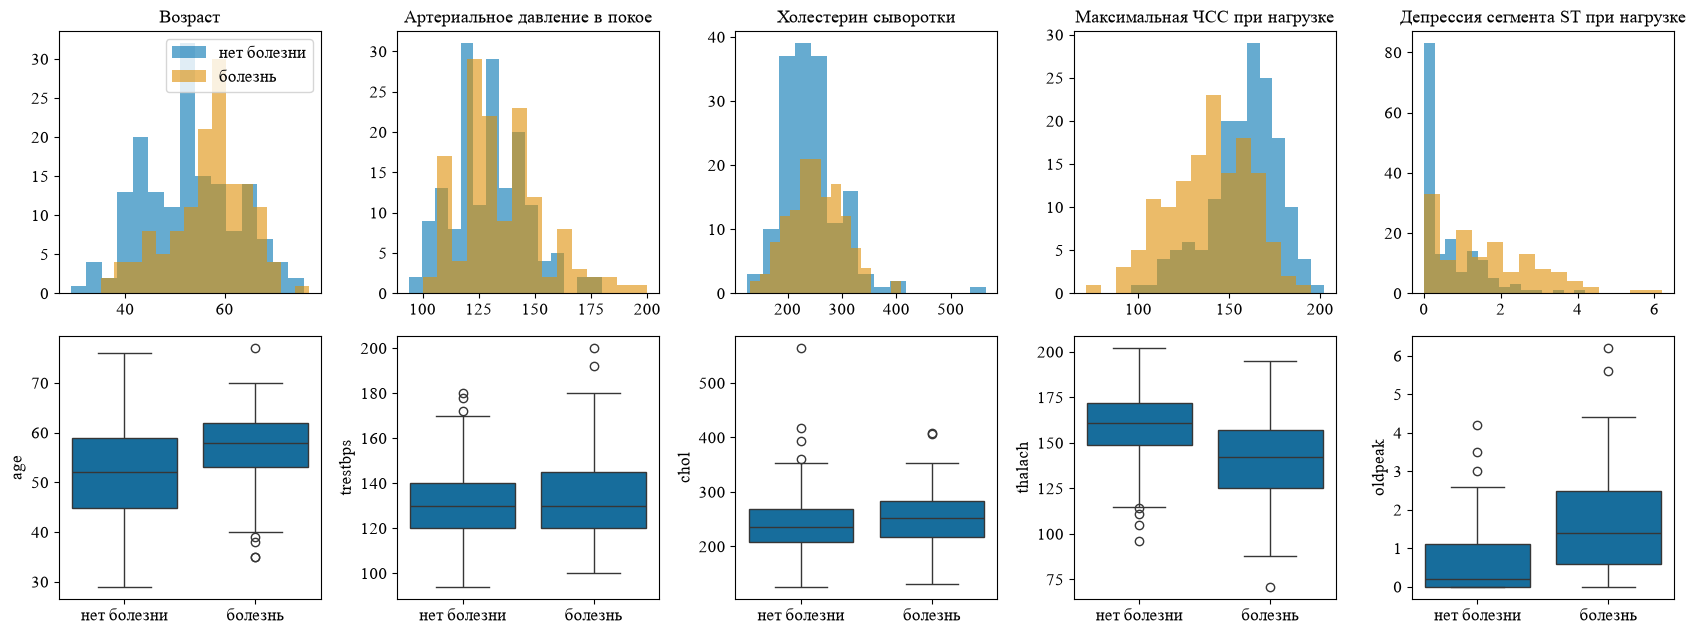

In [8]:
def plot_numeric(df):
    """Гистограммы и диаграммы размаха количественных признаков в разрезе диагноза."""
    fig, axes = plt.subplots(2, 5, figsize=(17, 6.5))
    for j, c in enumerate(NUMERIC):
        for t, lab in CODES["target"].items():
            axes[0, j].hist(df.loc[df.target == t, c], bins=15, alpha=0.6, label=lab)
        axes[0, j].set_title(DESCRIPTION[c].split(",")[0])
        sns.boxplot(x=df["target"].map(CODES["target"]), y=df[c], ax=axes[1, j])
        axes[1, j].set_xlabel("")
        axes[1, j].set_ylabel(c)
    axes[0, 0].legend()
    plt.tight_layout()
    savefig("fig_numeric")

plot_numeric(df)

**Функции и классы ячейки:**
- `plot_numeric` — гистограммы и диаграммы размаха количественных признаков в разрезе диагноза.

**Что делает ячейка.** Строит гистограммы (верхний ряд) и диаграммы размаха (нижний ряд) количественных признаков в разрезе диагноза. Диаграмма размаха: линия — медиана, ящик — от $Q_1$ до $Q_3$, «усы» — до $1{,}5\cdot IQR$, точки за усами — выбросы ($IQR=Q_3-Q_1$).

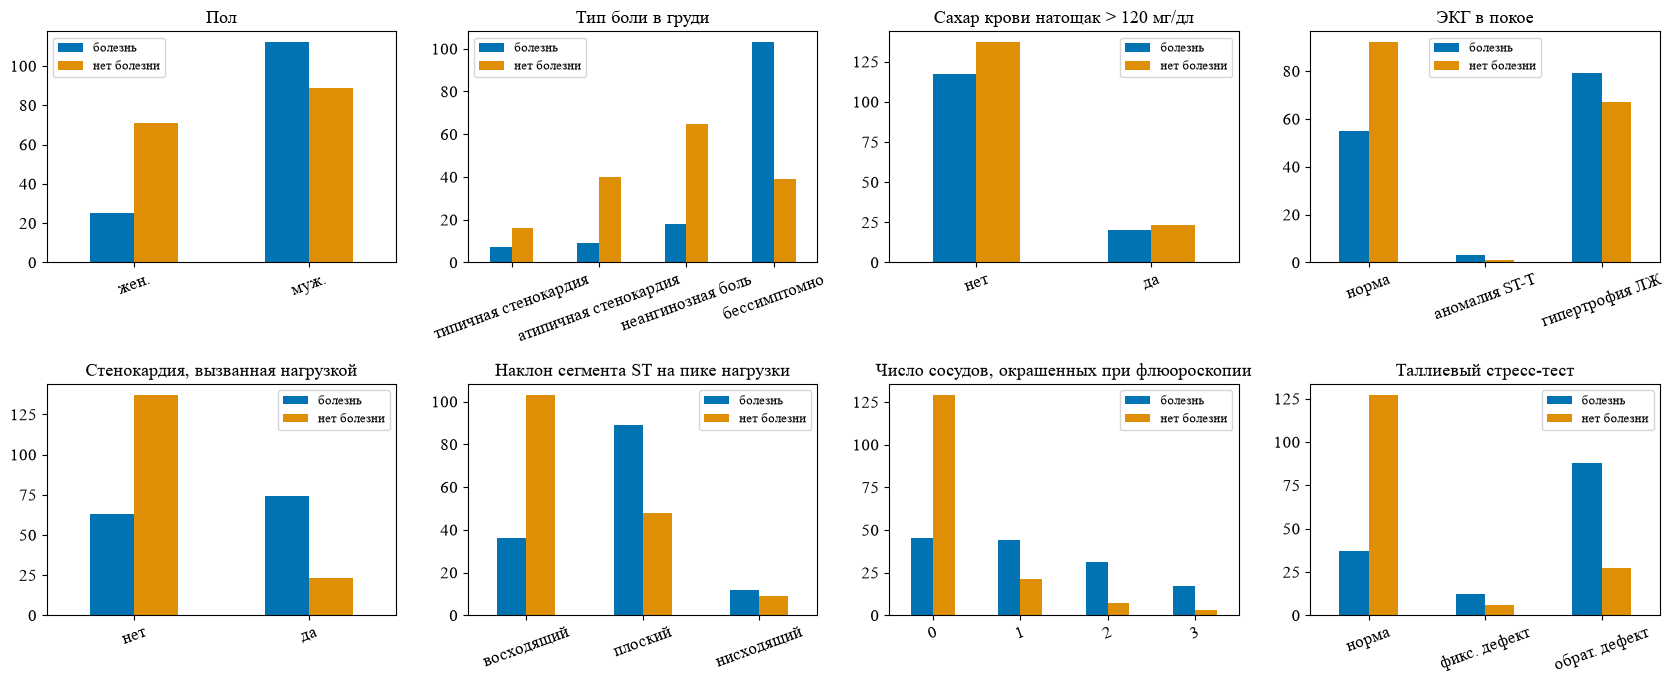

In [9]:
def plot_categorical(df):
    """Столбчатые диаграммы частот категорий каждого категориального признака с разбивкой по диагнозу."""
    fig, axes = plt.subplots(2, 4, figsize=(17, 7))
    for ax, c in zip(axes.ravel(), CATEGORICAL):
        ct = pd.crosstab(df[c].map(CODES[c]), df["target"].map(CODES["target"]))
        ct = ct.loc[[CODES[c][k] for k in sorted(df[c].unique())]]
        ct.plot(kind="bar", ax=ax, rot=20)
        ax.set_title(DESCRIPTION[c])
        ax.set_xlabel("")
        ax.legend(fontsize=9)
    plt.tight_layout()
    savefig("fig_categorical")

plot_categorical(df)

**Функции и классы ячейки:**
- `plot_categorical` — столбчатые диаграммы частот категорий каждого категориального признака с разбивкой по диагнозу.

**Что делает ячейка.** Строит столбчатые диаграммы частот категорий каждого категориального признака с разбивкой по диагнозу — позволяет визуально оценить, какие категории связаны с болезнью.

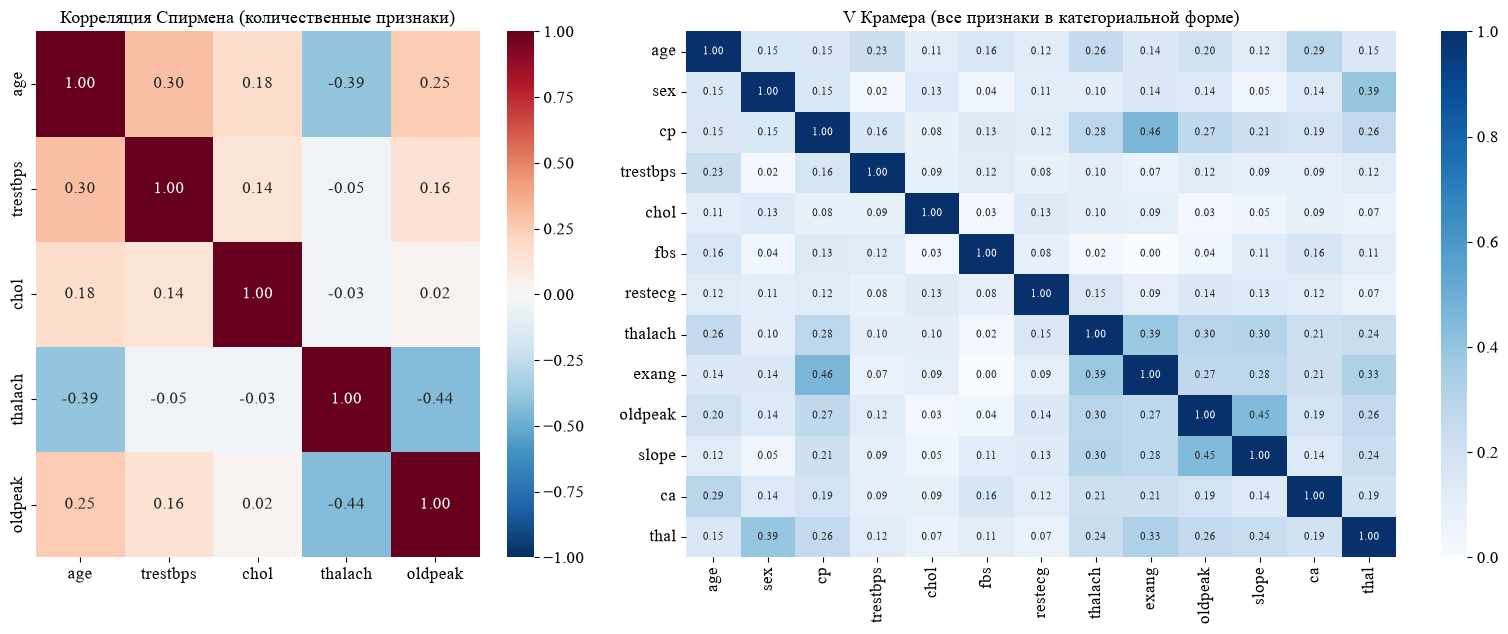

,feature,V,p
12,thal,0.527,0.000
2,cp,0.510,0.000
11,ca,0.493,0.000
8,exang,0.421,0.000
7,thalach,0.411,0.000
9,oldpeak,0.394,0.000
10,slope,0.383,0.000
1,sex,0.278,0.000
0,age,0.227,0.000
6,restecg,0.180,0.008


In [10]:
BINS = {
    "age": ([0, 49, 59, 200], ["<50", "50-59", ">=60"]),
    "trestbps": ([0, 119, 139, 1000], ["<120", "120-139", ">=140"]),
    "chol": ([0, 199, 239, 1000], ["<200", "200-239", ">=240"]),
    "oldpeak": ([-1, 0, 2, 100], ["0", "0-2", ">2"]),
}


def discretize(df):
    """Переводит количественные признаки в категориальные (3 уровня).

    age, trestbps, chol, oldpeak — по клиническим порогам (BINS);
    thalach — по терцилям выборки (клинической нормы нет).
    Категориальные признаки сохраняют коды. Возвращает (cat_df, thalach_edges).
    """
    out = pd.DataFrame(index=df.index)
    for c in FEATURES:
        if c in BINS:
            edges, labels = BINS[c]
            out[c] = pd.cut(df[c], edges, labels=labels).astype(str)
        elif c == "thalach":
            q = pd.qcut(df[c], 3, labels=["низкая", "средняя", "высокая"], retbins=True)
            out[c] = q[0].astype(str)
            thalach_edges = q[1]
        else:
            out[c] = df[c].astype(int).astype(str)
    return out, thalach_edges


def cramers_v(x, y):
    """Критерий хи-квадрат и коэффициент Крамера V = sqrt(chi2 / (n * (min(r, c) - 1))); возвращает (chi2, p, V)."""
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(ct, correction=False)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return chi2, p, v


def association_analysis(df, cat_all):
    """Связь признаков с диагнозом (V Крамера) и тепловые карты: Спирмен для количественных, V Крамера для всех."""
    assoc = []
    for c in FEATURES:
        chi2, p, v = cramers_v(cat_all[c], df["target"])
        assoc.append({"feature": c, "V": v, "p": p})
    assoc = pd.DataFrame(assoc).sort_values("V", ascending=False)
    assoc.to_csv(RES / "assoc_target.csv", index=False)

    vmat = pd.DataFrame(index=FEATURES, columns=FEATURES, dtype=float)
    for a in FEATURES:
        for b in FEATURES:
            vmat.loc[a, b] = 1.0 if a == b else cramers_v(cat_all[a], cat_all[b])[2]
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.6]})
    sns.heatmap(df[NUMERIC].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0])
    axes[0].set_title("Корреляция Спирмена (количественные признаки)")
    sns.heatmap(vmat.astype(float), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1], annot_kws={"size": 8})
    axes[1].set_title("V Крамера (все признаки в категориальной форме)")
    plt.tight_layout()
    savefig("fig_corr")
    return assoc

cat_all, thalach_edges = discretize(df)
assoc = association_analysis(df, cat_all)
show(assoc, 3)

**Функции и классы ячейки:**
- `discretize` — переводит количественные признаки в категориальные (3 уровня).
- `cramers_v` — критерий хи-квадрат и коэффициент Крамера V = sqrt(chi2 / (n * (min(r, c) - 1))); возвращает (chi2, p, V).
- `association_analysis` — связь признаков с диагнозом (V Крамера) и тепловые карты: Спирмен для количественных, V Крамера для всех.

**Что делает ячейка.** Оценивает связи между признаками:

- для количественных — коэффициент ранговой корреляции Спирмена (устойчив к выбросам и нелинейности): $\rho = 1-\frac{6\sum d_i^2}{n(n^2-1)}$, $d_i$ — разность рангов;
- для категориальных (и дискретизированных количественных) — коэффициент V Крамера на основе критерия $\chi^2$:

$$\chi^2=\sum_{a,b}\frac{(O_{ab}-E_{ab})^2}{E_{ab}},\quad E_{ab}=\frac{n_a n_b}{n},\qquad V=\sqrt{\frac{\chi^2}{n\,(\min(r,c)-1)}}\in[0,1]$$

Таблица `assoc` — сила связи каждого признака с диагнозом (используется только для интерпретации кластеров).

**Выводы дескриптивного анализа.** Пропусков после очистки нет. Признаки имеют разные шкалы и единицы измерения (от 0–6,2 мм у `oldpeak` до 126–564 мг/дл у `chol`), поэтому для мер расстояния нужна нормировка (в мере Гауэра — делением на размах). `chol` и `oldpeak` имеют правостороннюю асимметрию и выбросы (`chol` до 564 мг/дл, эксцесс 4,4), `thalach` — левостороннюю. Распределение диагноза сбалансировано (54 % / 46 %). Сильнее всего с диагнозом связаны `thal`, `cp`, `ca`, `exang`, `thalach`, `oldpeak`, `slope` (V > 0,38); `fbs`, `chol`, `trestbps` почти не связаны. Есть редкие категории (`restecg = 1` — 4 пациента, `thal = 6` — 18, `slope = 3` — 21).

## 4. Преобразование данных

In [11]:
def to_transactions(cat_df):
    """Каждая строка → транзакция из элементов вида «признак=значение»."""
    return [[f"{c}={v}" for c, v in zip(cat_df.columns, row)]
            for row in cat_df.itertuples(index=False)]


def to_long_table(cat_df):
    """Транзакционная таблица в формате Loginom: поля «Транзакция» (ID) и «Элемент» (item).

    Аналог узлов «Добавление ID» → «Свёртка столбцов» → «Калькулятор» (Concat).
    """
    long = cat_df.reset_index().melt(id_vars="index", var_name="feature", value_name="value")
    long["ID"] = long["index"] + 1
    long["item"] = long["feature"] + "=" + long["value"]
    return long.sort_values(["ID", "feature"])[["ID", "item"]].reset_index(drop=True)


def transform_data(cat_all, thalach_edges):
    """Пункт 4: таблица правил дискретизации, транзакции и транзакционная таблица для Loginom."""
    rows = []
    for c in NUMERIC:
        if c in BINS:
            rule = "; ".join(BINS[c][1])
            basis = "клинические пороги"
        else:
            rule = f"низкая ≤ {thalach_edges[1]:.0f}; средняя ≤ {thalach_edges[2]:.0f}; высокая > {thalach_edges[2]:.0f}"
            basis = "терцили выборки"
        vc = cat_all[c].value_counts()
        rows.append({"Признак": c, "Категории": rule, "Основание": basis,
                     "Частоты": "; ".join(f"{k}: {v}" for k, v in vc.items())})
    disc_tab = pd.DataFrame(rows)
    disc_tab.to_csv(RES / "discretization.csv", index=False)

    transactions = to_transactions(cat_all)
    long = to_long_table(cat_all)
    long.to_csv(DATA / "heart_transactions_loginom.csv", index=False)
    long.head(16).to_csv(RES / "long_fragment.csv", index=False)
    items = sorted({i for t in transactions for i in t})
    SUMMARY["transform"] = {"n_items": len(items), "len_tr": len(transactions[0]), "n_long": len(long),
                            "thalach_edges": [float(x) for x in thalach_edges]}
    print(f"Транзакций: {len(transactions)}, элементов в транзакции: {len(transactions[0])}, различных элементов: {len(items)}")
    print(transactions[0])
    return transactions, disc_tab

transactions, disc_tab = transform_data(cat_all, thalach_edges)
show(disc_tab)

Транзакций: 297, элементов в транзакции: 13, различных элементов: 38
['age=>=60', 'sex=1', 'cp=1', 'trestbps=>=140', 'chol=200-239', 'fbs=1', 'restecg=2', 'thalach=средняя', 'exang=0', 'oldpeak=>2', 'slope=3', 'ca=0', 'thal=6']


,Признак,Категории,Основание,Частоты
0,age,<50; 50-59; >=60,клинические пороги,50-59: 121; >=60: 91; <50: 85
1,trestbps,<120; 120-139; >=140,клинические пороги,120-139: 139; >=140: 98; <120: 60
2,chol,<200; 200-239; >=240,клинические пороги,>=240: 155; 200-239: 94; <200: 48
3,thalach,низкая ≤ 143; средняя ≤ 162; высокая > 162,терцили выборки,средняя: 107; низкая: 99; высокая: 91
4,oldpeak,0; 0-2; >2,клинические пороги,0-2: 151; 0: 96; >2: 50


**Функции и классы ячейки:**
- `to_transactions` — каждая строка → транзакция из элементов вида «признак=значение».
- `to_long_table` — транзакционная таблица в формате Loginom: поля «Транзакция» (ID) и «Элемент» (item).
- `transform_data` — пункт 4: таблица правил дискретизации, транзакции и транзакционная таблица для Loginom.

**Что делает ячейка.** CLOPE работает только с дискретными элементами, поэтому количественные признаки переводятся в 3 категории:

- `age`: < 50 / 50–59 / ≥ 60 лет;
- `trestbps`: < 120 (норма) / 120–139 (повышенное) / ≥ 140 мм рт. ст. (артериальная гипертензия);
- `chol`: < 200 (желательный) / 200–239 (пограничный) / ≥ 240 мг/дл (высокий, NCEP ATP III);
- `oldpeak`: 0 (нет депрессии ST) / (0; 2] / > 2 мм;
- `thalach`: клинической нормы нет (зависит от возраста), поэтому — терцили выборки (равные по численности группы).

Категориальные признаки остаются без изменений. Каждый пациент → транзакция из 13 элементов вида `признак=значение` (`to_transactions`). Функция `to_long_table` формирует таблицу «Транзакция — Элемент» — именно этот формат принимает узел «Кластеризация транзакций» Loginom (сохраняется в `data/heart_transactions_loginom.csv`, его можно импортировать в Loginom).

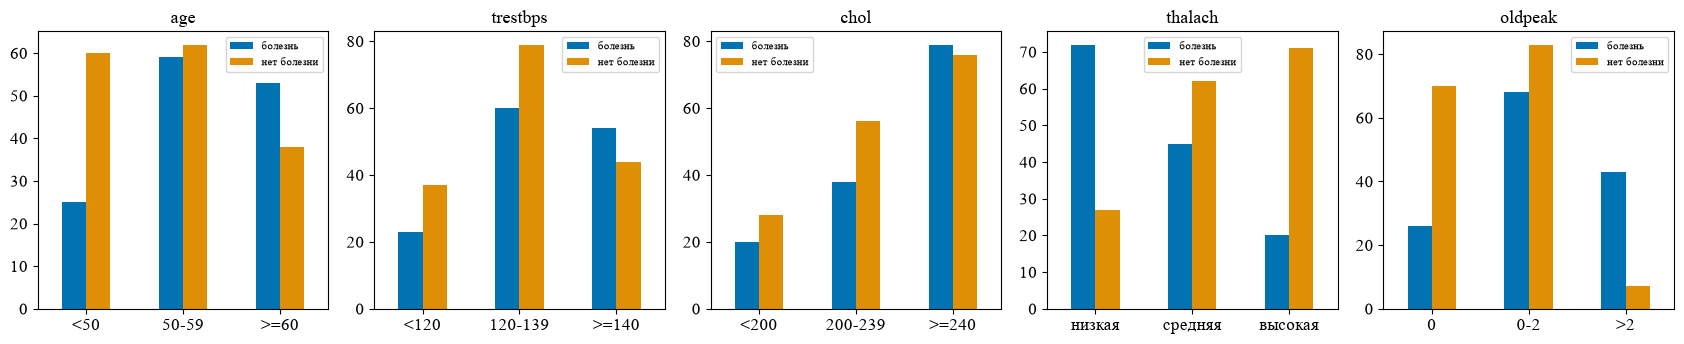

In [12]:
def plot_discrete(df, cat_all):
    """Распределения категорий дискретизированных количественных признаков в разрезе диагноза."""
    fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
    for ax, c in zip(axes, NUMERIC):
        order = BINS[c][1] if c in BINS else ["низкая", "средняя", "высокая"]
        pd.crosstab(cat_all[c], df["target"].map(CODES["target"])).loc[order].plot(kind="bar", ax=ax, rot=0)
        ax.set_title(c)
        ax.set_xlabel("")
        ax.legend(fontsize=8)
    plt.tight_layout()
    savefig("fig_discrete")

plot_discrete(df, cat_all)

**Функции и классы ячейки:**
- `plot_discrete` — распределения категорий дискретизированных количественных признаков в разрезе диагноза.

**Что делает ячейка.** Показывает распределения новых категорий количественных признаков в разрезе диагноза (проверка, что категории наполнены и сохраняют связь с исходными значениями).

## 5. Кластеризация методом CLOPE

### 5.1. Подбор коэффициента отталкивания *r*

CLOPE — эвристика: результат зависит от порядка просмотра транзакций. Поэтому для каждого $r\in[1;4]$ с шагом 0,1 (диапазон Loginom) алгоритм запускается при 50 случайных порядках и берётся решение с максимальным Profit (собственный критерий CLOPE). Profit при разных $r$ несравним, поэтому для выбора $r$ используются дополнительные характеристики решения.

In [13]:
MIN_SHARE = 0.05
R_GRID = np.round(np.arange(1.0, 4.001, 0.1), 1)
N_ORDERS = 50


def hamming_matrix(cat_df):
    """Нормированное расстояние Хэмминга: d(x, y) = (1/p) * sum_j [x_j != y_j]."""
    codes = np.column_stack([pd.factorize(cat_df[c])[0] for c in cat_df.columns])
    return (codes[:, None, :] != codes[None, :, :]).mean(axis=2)


def silhouette(D, labels):
    """Средний коэффициент силуэта по предвычисленной матрице расстояний D."""
    if len(set(labels)) < 2:
        return np.nan
    return metrics.silhouette_score(D, labels, metric="precomputed")


def stability(solutions):
    """Устойчивость: средний попарный ARI между разбиениями из разных запусков."""
    pairs = list(itertools.combinations(solutions, 2))
    return float(np.mean([metrics.adjusted_rand_score(a, b) for a, b in pairs]))


def merge_small_clusters(transactions, labels, r, min_share=0.05):
    """Переназначает транзакции мелких кластеров (доля < min_share) в крупные.

    Каждая транзакция мелкого кластера переносится в тот крупный кластер,
    для которого DeltaAdd максимально (тот же критерий, что в самом CLOPE).
    Возвращает новые метки, перенумерованные по убыванию размера.
    """
    labels = np.asarray(labels)
    sizes = np.bincount(labels)
    big = [k for k in range(len(sizes)) if sizes[k] >= min_share * len(labels)]
    clusters = {k: Cluster() for k in big}
    for t, lab in zip(transactions, labels):
        if lab in clusters:
            clusters[lab].add(t)
    out = labels.copy()
    for j, (t, lab) in enumerate(zip(transactions, labels)):
        if lab not in clusters:
            out[j] = max(big, key=lambda k: delta_add(clusters[k], t, r))
    return np.asarray(_relabel_by_size(list(out)))


def clope_grid_search(transactions, cat_all, y):
    """Пункт 5.1: перебор r из R_GRID, для каждого r — N_ORDERS случайных порядков транзакций.

    Для лучшего по Profit решения считаются число кластеров, число крупных
    кластеров, покрытие, силуэт по Хэммингу, устойчивость к порядку и
    (только для контроля) ARI и NMI с диагнозом. Возвращает (grid, best_by_r, H_mat).
    """
    n = len(transactions)
    H_mat = hamming_matrix(cat_all)
    grid, best_by_r = [], {}
    for r in R_GRID:
        runs = [clope(transactions, r=r, seed=s) for s in range(N_ORDERS)]
        best = max(runs, key=lambda x: x[1])
        labels = np.array(best[0])
        sizes = np.bincount(labels)
        k_large = int((sizes >= MIN_SHARE * n).sum())
        merged = merge_small_clusters(transactions, labels, r, MIN_SHARE) if k_large > 0 else labels
        merged_runs = []
        for lab, _, _, _ in runs:
            lab = np.array(lab)
            merged_runs.append(merge_small_clusters(transactions, lab, r, MIN_SHARE)
                               if (np.bincount(lab) >= MIN_SHARE * n).any() else lab)
        ext = external_metrics(y, merged)
        grid.append({"r": r, "k": len(sizes), "k_large": k_large,
                     "coverage": sizes[sizes >= MIN_SHARE * n].sum() / n, "profit": best[1],
                     "sil_H": silhouette(H_mat, merged), "stability": stability(merged_runs),
                     "ARI": ext["ARI"], "NMI": ext["NMI"]})
        best_by_r[r] = {"labels": labels, "merged": merged, "history": best[2], "n_iter": best[3]}
    grid = pd.DataFrame(grid)
    grid.round(4).to_csv(RES / "clope_grid.csv", index=False)
    return grid, best_by_r, H_mat

grid, best_by_r, H_mat = clope_grid_search(transactions, cat_all, y)
show(grid, 3)

,r,k,k_large,coverage,profit,sil_H,stability,ARI,NMI
0,1.0,1,1,1.000,101.605,NaN,1.000,0.000,0.000
1,1.1,2,1,0.987,70.797,NaN,0.960,0.000,0.000
2,1.2,2,1,0.987,49.340,NaN,0.883,0.000,0.000
3,1.3,2,1,0.987,34.386,NaN,0.846,0.000,0.000
4,1.4,2,1,0.987,23.964,NaN,0.681,0.000,0.000
5,1.5,2,1,0.987,16.701,NaN,0.621,0.000,0.000
6,1.6,2,1,0.987,11.639,NaN,0.533,0.000,0.000
7,1.7,3,1,0.987,8.112,NaN,0.346,0.000,0.000
8,1.8,3,1,0.987,5.653,NaN,0.326,0.000,0.000
9,1.9,3,1,0.987,3.940,NaN,0.199,0.000,0.000


**Функции и классы ячейки:**
- `hamming_matrix` — нормированное расстояние Хэмминга: d(x, y) = (1/p) * sum_j [x_j != y_j].
- `silhouette` — средний коэффициент силуэта по предвычисленной матрице расстояний D.
- `stability` — устойчивость: средний попарный ARI между разбиениями из разных запусков.
- `merge_small_clusters` — переназначает транзакции мелких кластеров (доля < min_share) в крупные.
- `clope_grid_search` — пункт 5.1: перебор r из R_GRID, для каждого r — N_ORDERS случайных порядков транзакций.

**Что делает ячейка.** Для каждого $r$:

- `k` — число кластеров CLOPE, `k_large` — число крупных кластеров (≥ 5 % выборки, ≥ 15 пациентов), `coverage` — доля пациентов в крупных кластерах;
- мелкие кластеры (< 5 %) переназначаются в крупные функцией `merge_small_clusters` — каждая транзакция идёт в тот крупный кластер, где максимально $\Delta Add$ (тот же критерий, что в CLOPE). Это аналог параметра «Ограничить число кластеров» Loginom, но без искажения процесса: сам CLOPE работает свободно;
- `sil_H` — силуэт по расстоянию Хэмминга (внутренняя метрика);
- `stability` — устойчивость к порядку транзакций: средний попарный ARI между 50 решениями;
- `ARI`, `NMI` — внешние метрики относительно диагноза (только для контроля, **в выборе r не участвуют**).

Расстояние Хэмминга между транзакциями (доля несовпадающих признаков):
$$d_H(x,y)=\frac1p\sum_{j=1}^{p}[x_j\neq y_j]$$

Выбранное r* = 2.7


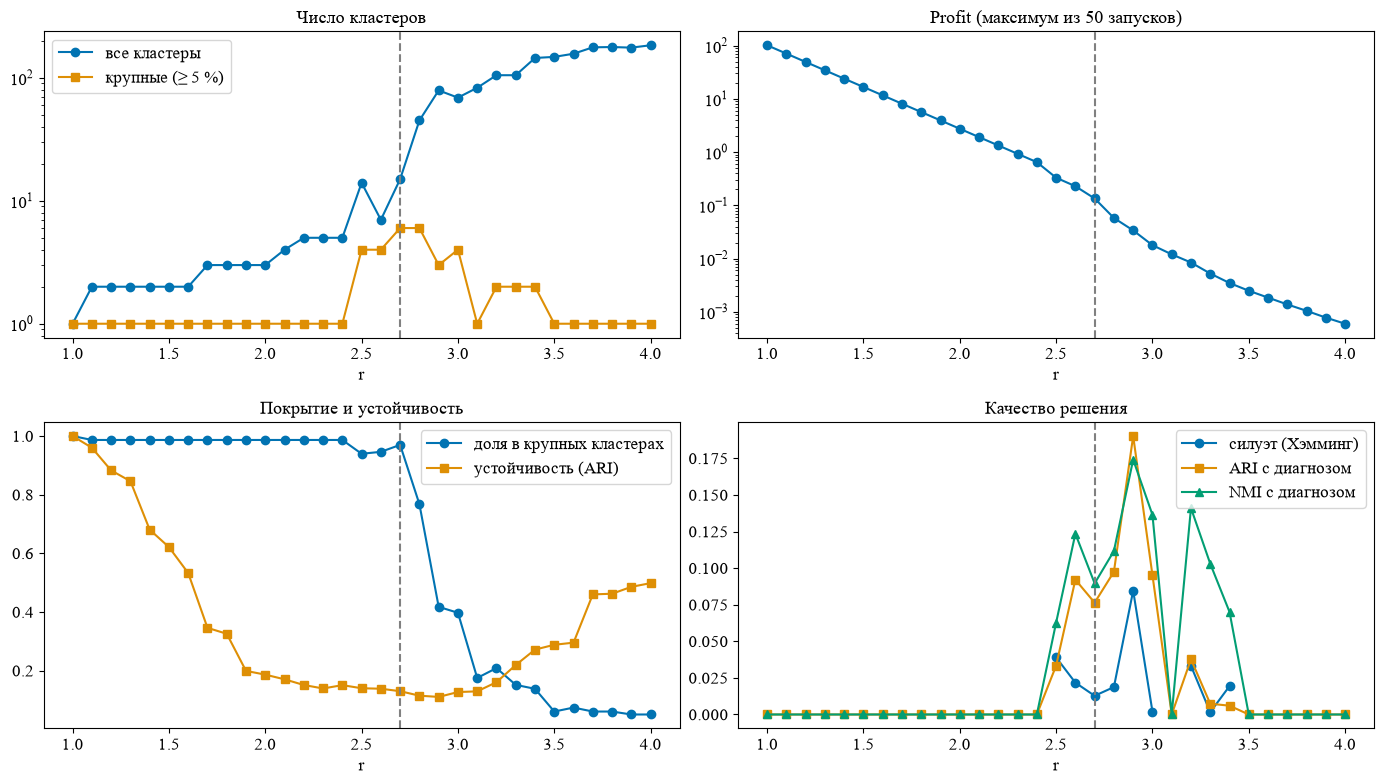

In [14]:
def choose_r(grid):
    """Выбор r*: не менее 3 крупных кластеров, максимум покрытия, при равенстве — максимум устойчивости."""
    cand = grid[(grid.k_large >= 3)]
    return float(cand.sort_values(["coverage", "stability"], ascending=False).iloc[0]["r"])


def plot_clope_grid(grid, r_star):
    """Графики числа кластеров, Profit, покрытия, устойчивости и качества решений CLOPE в зависимости от r."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    axes[0, 0].plot(grid.r, grid.k, "o-", label="все кластеры")
    axes[0, 0].plot(grid.r, grid.k_large, "s-", label="крупные (≥ 5 %)")
    axes[0, 0].set_yscale("log")
    axes[0, 0].set_title("Число кластеров")
    axes[0, 0].legend()
    axes[0, 1].plot(grid.r, grid.profit, "o-")
    axes[0, 1].set_yscale("log")
    axes[0, 1].set_title("Profit (максимум из 50 запусков)")
    axes[1, 0].plot(grid.r, grid.coverage, "o-", label="доля в крупных кластерах")
    axes[1, 0].plot(grid.r, grid.stability, "s-", label="устойчивость (ARI)")
    axes[1, 0].set_title("Покрытие и устойчивость")
    axes[1, 0].legend()
    axes[1, 1].plot(grid.r, grid.sil_H, "o-", label="силуэт (Хэмминг)")
    axes[1, 1].plot(grid.r, grid.ARI, "s-", label="ARI с диагнозом")
    axes[1, 1].plot(grid.r, grid.NMI, "^-", label="NMI с диагнозом")
    axes[1, 1].set_title("Качество решения")
    axes[1, 1].legend()
    for ax in axes.ravel():
        ax.axvline(r_star, color="grey", ls="--")
        ax.set_xlabel("r")
    plt.tight_layout()
    savefig("fig_clope_grid")

R_STAR = choose_r(grid)
print("Выбранное r* =", R_STAR)
plot_clope_grid(grid, R_STAR)

**Функции и классы ячейки:**
- `choose_r` — выбор r*: не менее 3 крупных кластеров, максимум покрытия, при равенстве — максимум устойчивости.
- `plot_clope_grid` — графики числа кластеров, Profit, покрытия, устойчивости и качества решений CLOPE в зависимости от r.

**Что делает ячейка.** Выбирает $r^*$ и строит графики характеристик решений в зависимости от $r$ (пунктир — выбранное значение).

**Правило выбора $r^*$:** решение должно содержать не менее трёх крупных кластеров (иначе это вырожденная структура «один большой кластер + выбросы»), а среди таких — максимальную долю пациентов в крупных кластерах (минимум «шума», который приходится переназначать); при равенстве — большая устойчивость. Правило использует только внутренние характеристики, диагноз не используется.

**Результат подбора.** Поведение CLOPE на этих данных имеет три режима:
- $r<2{,}5$ — почти все пациенты в одном кластере (Profit максимален при одном широком кластере), остальные — 1–4 «выброса» с редкими элементами (`restecg=1` и т.п.);
- $2{,}5\le r\le 3{,}0$ — переходная зона: появляются 3–6 крупных кластеров;
- $r>3{,}0$ — распад на сотни мелких кластеров из почти одинаковых транзакций (при $r=4$ — 184 кластера).

**Почему так происходит.** У каждого пациента ровно 13 элементов, и почти все 38 элементов встречаются в любой подгруппе пациентов. Например, при разбиении по диагнозу оба кластера имеют $W=38$, как и вся выборка, — Profit такого разбиения вдвое меньше, чем у одного кластера. CLOPE выгодно отделять группы, только если у них *разные наборы элементов* (малое $W$), как у грибов в демо-примере. В Heart Disease различия между группами — в *частотах* одних и тех же элементов, а не в их наличии. Кроме того, решения сильно зависят от порядка транзакций (устойчивость 0,11–0,14 в рабочей зоне).

Выбрано $r^* = 2{,}7$: 6 крупных кластеров содержат 97 % пациентов.

r* = 2.7: кластеров до объединения 15, размеры [171, 39, 22, 20, 19, 17, 1, 1, 1, 1, 1, 1, 1, 1, 1]
после объединения мелких: 6, размеры [171, 39, 25, 22, 20, 20], итераций 7


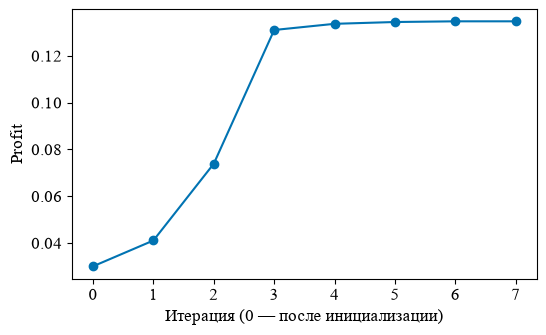

,cluster,N,W,S,H,G,"Доля болезни, %"
0,1,171,31,2223,71.710,2.313,35.088
1,2,39,29,507,17.483,0.603,84.615
2,3,25,37,325,8.784,0.237,32.000
3,4,22,30,286,9.533,0.318,81.818
4,5,20,35,260,7.429,0.212,65.000
5,6,20,29,260,8.966,0.309,25.000


In [15]:
def clope_final(transactions, best_by_r, r_star, y):
    """Пункт 5.2: итоговое решение CLOPE при r*, график Profit по итерациям и параметры кластеров.

    Возвращает (lab_raw, lab_clope, st_fin): метки до и после объединения мелких
    кластеров и таблицу N, W, S, H, G с долей больных.
    """
    sol = best_by_r[r_star]
    lab_raw = sol["labels"]
    lab_clope = sol["merged"]
    raw_sizes = np.bincount(lab_raw)
    print(f"r* = {r_star}: кластеров до объединения {len(raw_sizes)}, размеры {raw_sizes.tolist()}")
    print(f"после объединения мелких: {len(set(lab_clope))}, размеры {np.bincount(lab_clope).tolist()}, итераций {sol['n_iter']}")

    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.plot(range(len(sol["history"])), sol["history"], "o-")
    ax.set_xlabel("Итерация (0 — после инициализации)")
    ax.set_ylabel("Profit")
    savefig("fig_clope_history")

    st_raw = pd.DataFrame(cluster_stats(transactions, lab_raw))
    st_fin = pd.DataFrame(cluster_stats(transactions, lab_clope))
    st_fin["Доля болезни, %"] = [100 * y[lab_clope == k].mean() for k in st_fin.cluster]
    st_fin["cluster"] = st_fin["cluster"] + 1
    st_fin.round(3).to_csv(RES / "clope_clusters.csv", index=False)
    st_raw.to_csv(RES / "clope_clusters_raw.csv", index=False)
    SUMMARY["clope"] = {"r": r_star, "k_raw": int(len(raw_sizes)), "raw_sizes": raw_sizes.tolist(),
                        "k": len(set(lab_clope)), "sizes": np.bincount(lab_clope).tolist(), "n_iter": sol["n_iter"],
                        "history": sol["history"], "profit_raw": float(sol["history"][-1]),
                        "profit_merged": profit(list(build_clusters(transactions, lab_clope).values()), r_star)}
    return lab_raw, lab_clope, st_fin

lab_raw, lab_clope, st_fin = clope_final(transactions, best_by_r, R_STAR, y)
K_CLOPE = len(set(lab_clope))
show(st_fin, 3)

**Функции и классы ячейки:**
- `clope_final` — пункт 5.2: итоговое решение CLOPE при r*, график Profit по итерациям и параметры кластеров.

**Что делает ячейка.** Берёт лучшее решение для $r^*$, показывает размеры кластеров до и после объединения мелких, строит график роста Profit по итерациям (фаза 1 — инициализация, далее итерации перемещения, пока есть перемещения) и таблицу параметров кластеров (N, W, S, H = S/W, G = S/W², доля больных — только для интерпретации).

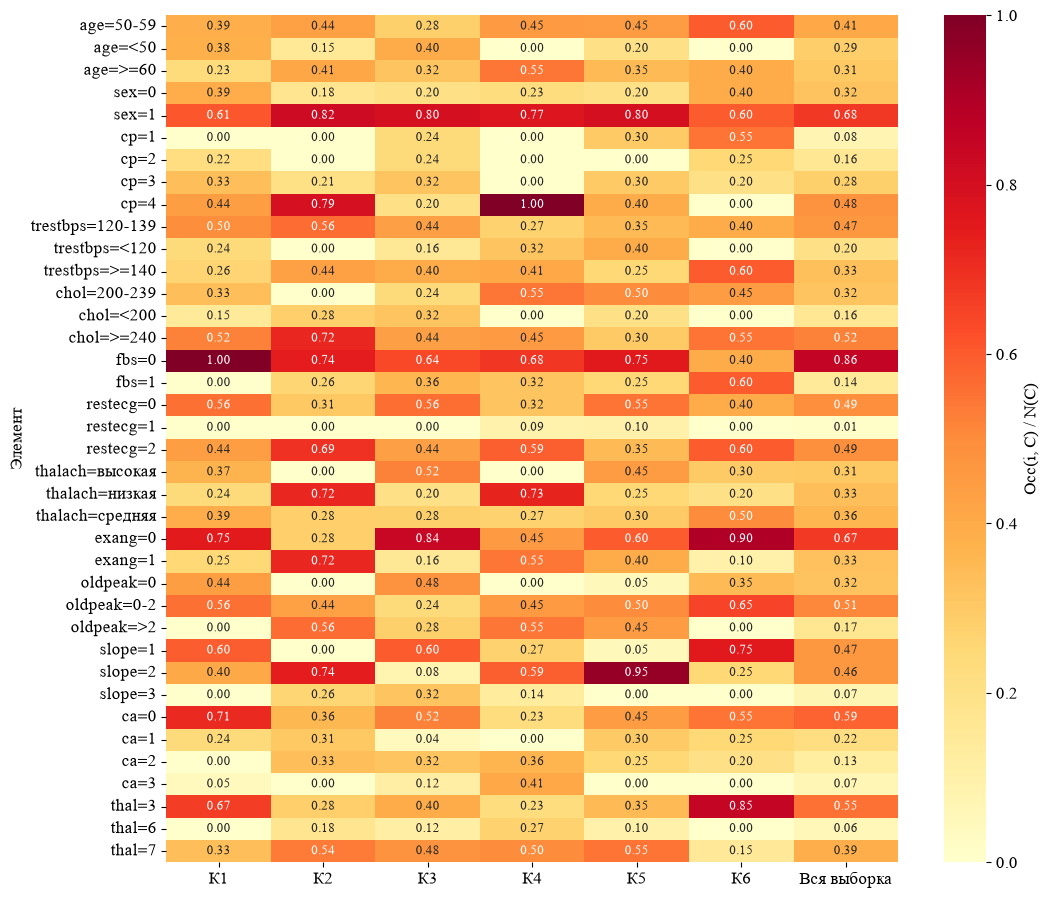

,Кластер,N,Характерные элементы (доля в кластере)
0,К1,171,
1,К2,39,cp=4 (0.79); slope=2 (0.74); chol=>=240 (0.72)...
2,К3,25,thalach=высокая (0.52)
3,К4,22,cp=4 (1.00); thalach=низкая (0.73); age=>=60 (...
4,К5,20,slope=2 (0.95); thal=7 (0.55); chol=200-239 (0...
5,К6,20,exang=0 (0.90); thal=3 (0.85); slope=1 (0.75);...


In [16]:
def item_profile(transactions, labels):
    """Нормированная гистограмма CLOPE: доля транзакций кластера, содержащих элемент, Occ(i, C) / N(C)."""
    labels = np.asarray(labels)
    rows = {}
    for t, lab in zip(transactions, labels):
        for i in t:
            rows.setdefault(i, {}).setdefault(lab, 0)
            rows[i][lab] += 1
    prof = pd.DataFrame(rows).T.fillna(0)
    prof = prof[sorted(prof.columns)]
    sizes = pd.Series(labels).value_counts().sort_index()
    return prof / sizes.values


def clope_item_profiles(transactions, lab_clope):
    """Пункт 5.3: тепловая карта профиля элементов и характерные элементы кластеров (доля ≥ 0,5 и lift ≥ 1,3)."""
    n = len(transactions)
    prof = item_profile(transactions, lab_clope)
    prof.columns = [f"К{k + 1}" for k in prof.columns]
    overall = pd.Series({i: sum(i in t for t in transactions) / n for i in prof.index})
    prof_sorted = prof.loc[sorted(prof.index, key=lambda i: (FEATURES.index(i.split("=")[0]), i))]
    fig, ax = plt.subplots(figsize=(1.3 * prof.shape[1] + 4, 11))
    sns.heatmap(prof_sorted.assign(**{"Вся выборка": overall[prof_sorted.index]}), annot=True, fmt=".2f",
                cmap="YlOrRd", ax=ax, cbar_kws={"label": "Occ(i, C) / N(C)"}, annot_kws={"size": 9})
    ax.set_ylabel("Элемент")
    savefig("fig_clope_items")

    rows = []
    for k, col in enumerate(prof.columns):
        lift = prof[col] / overall[prof.index]
        top = prof[(prof[col] >= 0.5) & (lift >= 1.3)][col].sort_values(ascending=False)
        rows.append({"Кластер": col, "N": int((lab_clope == k).sum()),
                     "Характерные элементы (доля в кластере)": "; ".join(f"{i} ({v:.2f})" for i, v in top.items())})
    char_tab = pd.DataFrame(rows)
    char_tab.to_csv(RES / "clope_char.csv", index=False)
    return char_tab

char_tab = clope_item_profiles(transactions, lab_clope)
show(char_tab)

**Функции и классы ячейки:**
- `item_profile` — нормированная гистограмма CLOPE: доля транзакций кластера, содержащих элемент, Occ(i, C) / N(C).
- `clope_item_profiles` — пункт 5.3: тепловая карта профиля элементов и характерные элементы кластеров (доля ≥ 0,5 и lift ≥ 1,3).

**Что делает ячейка.** Строит профиль элементов кластеров — нормированную гистограмму CLOPE $Occ(i,C)/N(C)$ (доля транзакций кластера, содержащих элемент $i$); последний столбец — доля по всей выборке. Характерные элементы кластера — те, что встречаются не менее чем у половины его транзакций и в 1,3 раза чаще, чем в среднем по выборке (lift):

$$lift(i, C)=\frac{Occ(i,C)/N(C)}{Occ(i,D)/|D|}$$

**Интерпретация кластеров CLOPE ($r^*=2{,}7$):**
- **К1 (171 чел., 35 % больных)** — «основная масса»: умеренные профили; кластер определяется в первую очередь *отсутствием* редких элементов (у всех `fbs=0`, нет `oldpeak>2`, `slope=3`, `thal=6`, `ca=2`, `cp=1`) — так CLOPE удерживает малую ширину $W=31$ самого большого кластера;
- **К2 (39 чел., 85 % больных)** — классическая ишемическая картина: бессимптомная боль (79 %), стенокардия нагрузки (72 %), низкая максимальная ЧСС (72 %), плоский сегмент ST (74 %), депрессия ST > 2 мм (56 %), обратимый дефект перфузии (54 %);
- **К4 (22 чел., 82 % больных)** — пожилые пациенты (нет моложе 50 лет) с бессимптомной болью (100 %), многососудистым поражением (`ca=3` — 41 %), низкой ЧСС и выраженной депрессией ST;
- **К5 (20 чел., 65 % больных)** — плоский сегмент ST (95 %) и обратимый дефект (55 %);
- **К6 (20 чел., 25 % больных)** — гипертоники (АД ≥ 140 — 60 %) с повышенным сахаром (60 %) и типичной стенокардией (55 %), но без ишемии на нагрузке (`exang=0` — 90 %, `thal=3` — 85 %);
- **К3 (25 чел., 32 % больных)** — «сборный» кластер с шириной $W=37$ (почти все элементы), характерна лишь высокая ЧСС.

Таким образом, CLOPE выделил две небольшие группы «тяжёлых» больных (К2, К4), но основная часть больных (60 из 137) осталась в общем кластере К1.

In [17]:
GOWER_NUMERIC = NUMERIC + ["ca"]
GOWER_NOMINAL = [c for c in CATEGORICAL if c != "ca"]


def gower_matrix(df, numeric, categorical, weights=None):
    """Матрица расстояний Гауэра для смешанных данных.

    d(i, j) = sum_f w_f * delta_ijf / sum_f w_f, где
    delta_ijf = |x_if - x_jf| / R_f для количественных (и порядковых) признаков,
    R_f — размах признака f; delta_ijf = [x_if != x_jf] для номинальных.
    """
    cols = list(numeric) + list(categorical)
    w = np.ones(len(cols)) if weights is None else np.asarray(weights, float)
    n = len(df)
    total = np.zeros((n, n))
    for f, c in enumerate(cols):
        x = df[c].to_numpy()
        if c in numeric:
            x = x.astype(float)
            rng = x.max() - x.min()
            delta = np.abs(x[:, None] - x[None, :]) / rng if rng > 0 else np.zeros((n, n))
        else:
            delta = (x[:, None] != x[None, :]).astype(float)
        total += w[f] * delta
    return total / w.sum()


def evaluate_solution(labels, y, H_mat, G_mat):
    """Внешние метрики относительно диагноза и средний силуэт по Хэммингу и по Гауэру."""
    m = external_metrics(y, labels)
    m["Silhouette (Хэмминг)"] = silhouette(H_mat, labels)
    m["Silhouette (Гауэр)"] = silhouette(G_mat, labels)
    return m


def diagnosis_crosstab(labels, df, name):
    """Кросс-таблица «кластер × диагноз» (кластеры нумеруются с 1)."""
    return pd.crosstab(pd.Series(labels + 1, name=name), pd.Series(df["target"].map(CODES["target"]), name="Диагноз"))

G_mat = gower_matrix(df, GOWER_NUMERIC, GOWER_NOMINAL)
m_clope = evaluate_solution(lab_clope, y, H_mat, G_mat)
ct_clope = diagnosis_crosstab(lab_clope, df, "Кластер CLOPE")
SUMMARY["clope"]["metrics"] = m_clope
SUMMARY["clope"]["ct"] = ct_clope.to_dict("index")
show(pd.Series(m_clope), 4)
show(ct_clope)

ARI                     0.0764
NMI                     0.0896
Homogeneity             0.1323
Completeness            0.0677
V-measure               0.0896
Purity                  0.6970
Silhouette (Хэмминг)    0.0128
Silhouette (Гауэр)      0.0154
dtype: float64

Диагноз,болезнь,нет болезни
Кластер CLOPE,,
1,60,111
2,33,6
3,8,17
4,18,4
5,13,7
6,5,15


**Функции и классы ячейки:**
- `gower_matrix` — матрица расстояний Гауэра для смешанных данных.
- `evaluate_solution` — внешние метрики относительно диагноза и средний силуэт по Хэммингу и по Гауэру.
- `diagnosis_crosstab` — кросс-таблица «кластер × диагноз» (кластеры нумеруются с 1).

**Что делает ячейка.** Считает метрики качества итогового решения CLOPE.

*Внутренние метрики.* Силуэт объекта $i$:
$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}}\in[-1;1],$$
$a(i)$ — среднее расстояние до объектов своего кластера, $b(i)$ — минимальное среднее расстояние до объектов другого кластера. Средний силуэт > 0,5 — чёткая структура, 0,25–0,5 — умеренная, < 0,25 — слабая. Считается по Хэммингу (мера, «родная» для категориальных транзакций) и по Гауэру (для сравнения с PAM).

*Внешние метрики* (эталон — диагноз):

- скорректированный индекс Рэнда: $ARI=\dfrac{RI-E[RI]}{\max(RI)-E[RI]}$, где $RI$ — доля согласованных пар объектов; $ARI\approx0$ — случайное разбиение, 1 — полное совпадение;
- нормированная взаимная информация: $NMI(U,V)=\dfrac{2\,I(U,V)}{H(U)+H(V)}$, $I(U,V)=\sum_{u,v}p_{uv}\log\dfrac{p_{uv}}{p_u p_v}$;
- однородность $h=1-\dfrac{H(K\mid C)}{H(K)}$ (каждый кластер — один класс), полнота $c=1-\dfrac{H(C\mid K)}{H(C)}$ (класс — в одном кластере), V-мера $V=\dfrac{2hc}{h+c}$;
- чистота $Purity=\dfrac1n\sum_k\max_j |C_k\cap K_j|$.

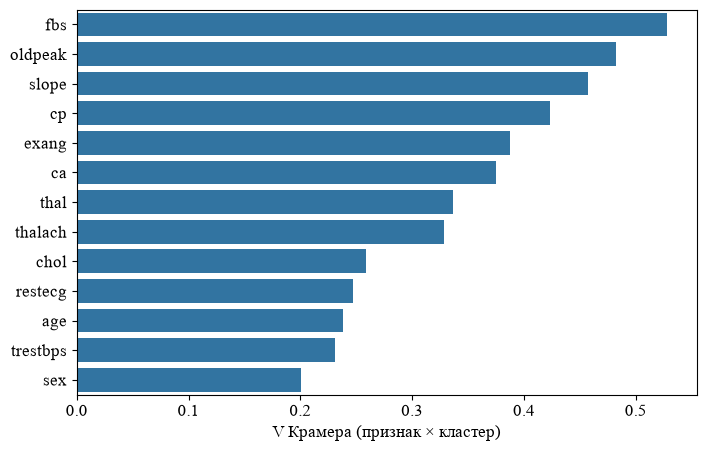

,feature,chi2,p_chi2,V,H,p_H,eta2,description
0,fbs,82.8285,0.0000,0.5281,NaN,NaN,NaN,Сахар крови натощак > 120 мг/дл
1,oldpeak,137.9611,0.0000,0.4819,106.2155,0.0000,0.3478,"Депрессия сегмента ST при нагрузке, мм"
2,slope,124.0743,0.0000,0.4570,NaN,NaN,NaN,Наклон сегмента ST на пике нагрузки
3,cp,159.7591,0.0000,0.4234,NaN,NaN,NaN,Тип боли в груди
4,exang,44.6535,0.0000,0.3877,NaN,NaN,NaN,"Стенокардия, вызванная нагрузкой"
5,ca,124.9883,0.0000,0.3745,NaN,NaN,NaN,"Число сосудов, окрашенных при флюороскопии"
6,thal,67.2709,0.0000,0.3365,NaN,NaN,NaN,Таллиевый стресс-тест
7,thalach,64.1020,0.0000,0.3285,54.5849,0.0000,0.1704,"Максимальная ЧСС при нагрузке, уд/мин"
8,chol,39.7616,0.0000,0.2587,10.1958,0.0699,0.0179,"Холестерин сыворотки, мг/дл"
9,restecg,36.3114,0.0001,0.2472,NaN,NaN,NaN,ЭКГ в покое


In [18]:
def kruskal_eta2(x, labels):
    """Критерий Краскела–Уоллиса и размер эффекта eta^2_H = (H - k + 1) / (n - k); возвращает (H, p, eta2)."""
    labels = np.asarray(labels)
    groups = [x[labels == g] for g in np.unique(labels)]
    h, p = stats.kruskal(*groups)
    k, n = len(groups), len(x)
    return h, p, (h - k + 1) / (n - k)


def feature_significance(cat_df, num_df, labels, descriptions=None):
    """Значимость признаков для разбиения.

    Для всех признаков (в категориальной форме) — хи-квадрат и V Крамера;
    для исходных количественных — дополнительно Краскел–Уоллис и eta^2_H.
    Таблица упорядочена по убыванию V Крамера.
    """
    rows = []
    for c in cat_df.columns:
        chi2, p, v = cramers_v(cat_df[c].to_numpy(), np.asarray(labels))
        row = {"feature": c, "chi2": chi2, "p_chi2": p, "V": v,
               "H": np.nan, "p_H": np.nan, "eta2": np.nan}
        if num_df is not None and c in num_df.columns:
            h, ph, e = kruskal_eta2(num_df[c].to_numpy(), labels)
            row.update({"H": h, "p_H": ph, "eta2": e})
        if descriptions:
            row["description"] = descriptions.get(c, c)
        rows.append(row)
    return pd.DataFrame(rows).sort_values("V", ascending=False).reset_index(drop=True)


def clope_significance(cat_all, df, lab_clope):
    """Пункт 5.5: значимость признаков для разбиения CLOPE и столбчатая диаграмма V Крамера."""
    sig = feature_significance(cat_all, df[NUMERIC], lab_clope, DESCRIPTION)
    sig.round(4).to_csv(RES / "clope_significance.csv", index=False)
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(data=sig, y="feature", x="V", ax=ax, color="tab:blue")
    ax.set_xlabel("V Крамера (признак × кластер)")
    ax.set_ylabel("")
    savefig("fig_clope_sig")
    return sig

sig_clope = clope_significance(cat_all, df, lab_clope)
show(sig_clope, 4)

**Функции и классы ячейки:**
- `kruskal_eta2` — критерий Краскела–Уоллиса и размер эффекта eta^2_H = (H - k + 1) / (n - k); возвращает (H, p, eta2).
- `feature_significance` — значимость признаков для разбиения.
- `clope_significance` — пункт 5.5: значимость признаков для разбиения CLOPE и столбчатая диаграмма V Крамера.

**Что делает ячейка.** Оценивает значимость признаков для разбиения CLOPE:

- для каждого признака (в категориальной форме) — критерий $\chi^2$ независимости «признак × кластер», p-value и V Крамера (сила связи, сравнима между признаками);
- для исходных количественных признаков дополнительно — критерий Краскела–Уоллиса (непараметрический аналог однофакторного ANOVA) и размер эффекта:

$$H=\frac{12}{n(n+1)}\sum_{g=1}^{k}\frac{R_g^2}{n_g}-3(n+1),\qquad \eta^2_H=\frac{H-k+1}{n-k},$$

$R_g$ — сумма рангов в кластере $g$. p < 0,05 — признак значимо различается между кластерами. Шкала V Крамера: < 0,1 — слабая, 0,1–0,3 — умеренная, > 0,3 — сильная связь.

**Результат.** Все признаки значимы (p < 0,05), но наибольший V Крамера — у `fbs` (0,53), клинически почти не связанного с диагнозом (V = 0,003). Это следствие механизма CLOPE: редкий элемент `fbs=1` (14 % пациентов) увеличивает ширину кластера, поэтому все такие пациенты «вытеснены» из большого кластера К1. Далее идут `oldpeak`, `slope`, `cp`, `exang`, `ca`, `thal` — признаки ишемии. Внутренние метрики около нуля (силуэт 0,01), т.е. по Хэммингу кластеры почти не отделены друг от друга.

## 6. Кластеризация смешанных данных: мера Гауэра + PAM

### 6.1. Мера Гауэра

In [19]:
def gower_contributions(df, numeric, categorical, i, j):
    """Покомпонентные вклады delta_ijf в расстояние Гауэра между объектами i и j."""
    rows = []
    for c in list(numeric) + list(categorical):
        xi, xj = df[c].iloc[i], df[c].iloc[j]
        if c in numeric:
            rng = df[c].max() - df[c].min()
            rows.append((c, xi, xj, abs(xi - xj) / rng))
        else:
            rows.append((c, xi, xj, float(xi != xj)))
    return pd.DataFrame(rows, columns=["feature", "x_i", "x_j", "delta"])


def gower_example(df, G_mat):
    """Пункт 6.1: характеристики матрицы Гауэра и пример расчёта расстояния между пациентами 0 и 1."""
    n = len(df)
    print("Размер матрицы:", G_mat.shape, " среднее расстояние:", round(G_mat[np.triu_indices(n, 1)].mean(), 4))
    contrib = gower_contributions(df, GOWER_NUMERIC, GOWER_NOMINAL, 0, 1)
    contrib.to_csv(RES / "gower_example.csv", index=False)
    SUMMARY["gower_example"] = {"d01": float(G_mat[0, 1]), "mean": float(G_mat[np.triu_indices(n, 1)].mean())}
    print("d(0, 1) =", round(G_mat[0, 1], 4), "= среднее вкладов", round(contrib.delta.mean(), 4))
    return contrib

contrib = gower_example(df, G_mat)
show(contrib, 4)

Размер матрицы: (297, 297)  среднее расстояние: 0.3576
d(0, 1) = 0.5227 = среднее вкладов 0.5227


,feature,x_i,x_j,delta
0,age,63.0,67.0,0.0833
1,trestbps,145.0,160.0,0.1415
2,chol,233.0,286.0,0.1210
3,thalach,150.0,108.0,0.3206
4,oldpeak,2.3,1.5,0.1290
5,ca,0.0,3.0,1.0000
6,sex,1.0,1.0,0.0000
7,cp,1.0,4.0,1.0000
8,fbs,1.0,0.0,1.0000
9,restecg,2.0,2.0,0.0000


**Функции и классы ячейки:**
- `gower_contributions` — покомпонентные вклады delta_ijf в расстояние Гауэра между объектами i и j.
- `gower_example` — пункт 6.1: характеристики матрицы Гауэра и пример расчёта расстояния между пациентами 0 и 1.

**Что делает ячейка.** Вычисляет матрицу расстояний Гауэра по **исходным** данным (без дискретизации) и, для примера, вклады всех признаков в расстояние между пациентами 0 и 1.

$$d_G(i,j)=\frac{\sum_{f=1}^{p} w_{ijf}\,\delta_{ijf}}{\sum_{f=1}^{p} w_{ijf}}$$

- количественный (и порядковый `ca`) признак: $\delta_{ijf}=\dfrac{|x_{if}-x_{jf}|}{R_f}$, $R_f=\max x_f-\min x_f$ — нормировка размахом приводит все признаки к [0; 1];
- номинальный признак: $\delta_{ijf}=0$, если $x_{if}=x_{jf}$, иначе 1;
- $w_{ijf}=0$, если значение пропущено (у нас пропусков нет, все веса 1).

Мера Гауэра позволяет не терять информацию количественных признаков (не нужна дискретизация, как для CLOPE) и одновременно корректно учитывать категориальные.

### 6.2. Подбор числа кластеров для PAM

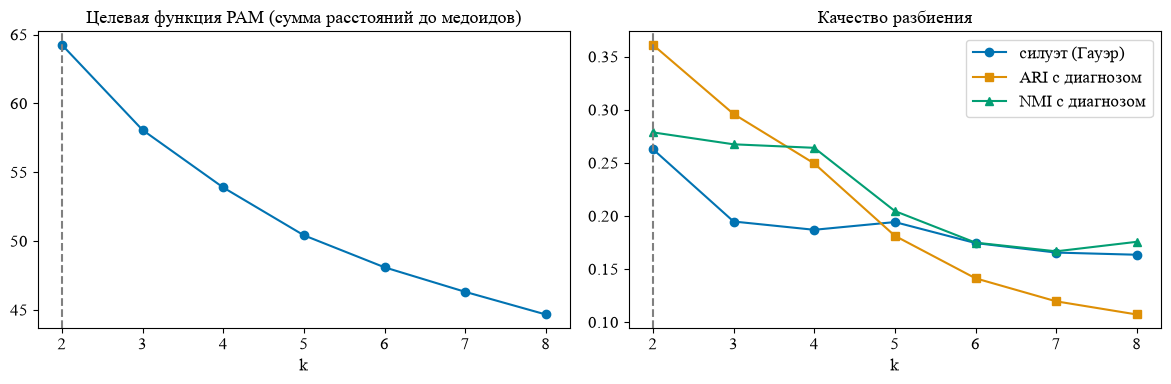

Выбрано k = 2


,k,cost,sil_G,min_share,ARI,NMI
0,2,64.2515,0.2628,0.4377,0.3611,0.2786
1,3,58.0621,0.1947,0.2761,0.2960,0.2674
2,4,53.8854,0.1869,0.2054,0.2494,0.2641
3,5,50.4131,0.1942,0.1380,0.1812,0.2046
4,6,48.0877,0.1744,0.1077,0.1412,0.1748
5,7,46.3047,0.1654,0.0976,0.1195,0.1666
6,8,44.6590,0.1634,0.0943,0.1071,0.1756


In [20]:
def pam(D, k, max_iter=100):
    """Алгоритм PAM (Partitioning Around Medoids, Kaufman & Rousseeuw).

    Минимизирует E = sum_i d(x_i, m_c(i)) — сумму расстояний объектов до
    ближайшего медоида. BUILD: жадный выбор k начальных медоидов. SWAP:
    перебор замен «медоид ↔ не медоид», принимается замена с наибольшим
    уменьшением E, пока такие замены существуют.

    Возвращает (labels, medoids, cost); кластеры перенумерованы по убыванию размера.
    """
    n = D.shape[0]
    medoids = [int(np.argmin(D.sum(axis=1)))]
    while len(medoids) < k:
        nearest = D[:, medoids].min(axis=1)
        gains = np.array([np.maximum(nearest - D[:, c], 0).sum() if c not in medoids else -1
                          for c in range(n)])
        medoids.append(int(np.argmax(gains)))

    cost = D[:, medoids].min(axis=1).sum()
    for _ in range(max_iter):
        best = (0.0, None, None)
        for mi in range(k):
            for h in range(n):
                if h in medoids:
                    continue
                cand = medoids.copy()
                cand[mi] = h
                new_cost = D[:, cand].min(axis=1).sum()
                if new_cost - cost < best[0] - 1e-12:
                    best = (new_cost - cost, mi, h)
        if best[1] is None:
            break
        medoids[best[1]] = best[2]
        cost += best[0]

    labels = np.argmin(D[:, medoids], axis=1)
    order = np.argsort(-np.bincount(labels, minlength=k))
    remap = np.empty(k, int)
    remap[order] = np.arange(k)
    return remap[labels], [medoids[o] for o in order], float(cost)


def pam_grid_search(G_mat, y):
    """Пункт 6.2: PAM для k = 2..8 по матрице Гауэра; выбор k по максимуму среднего силуэта.

    Возвращает (pam_grid, pam_sol, k_best).
    """
    n = G_mat.shape[0]
    rows, sol = [], {}
    for k in range(2, 9):
        lab, med, cost = pam(G_mat, k)
        ext = external_metrics(y, lab)
        rows.append({"k": k, "cost": cost, "sil_G": silhouette(G_mat, lab),
                     "min_share": np.bincount(lab).min() / n, "ARI": ext["ARI"], "NMI": ext["NMI"]})
        sol[k] = (lab, med, cost)
    grid = pd.DataFrame(rows)
    k_best = int(grid.loc[grid.sil_G.idxmax(), "k"])
    grid.round(4).to_csv(RES / "pam_grid.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(grid.k, grid.cost, "o-")
    axes[0].set_title("Целевая функция PAM (сумма расстояний до медоидов)")
    axes[1].plot(grid.k, grid.sil_G, "o-", label="силуэт (Гауэр)")
    axes[1].plot(grid.k, grid.ARI, "s-", label="ARI с диагнозом")
    axes[1].plot(grid.k, grid.NMI, "^-", label="NMI с диагнозом")
    axes[1].legend()
    axes[1].set_title("Качество разбиения")
    for ax in axes:
        ax.set_xlabel("k")
        ax.axvline(k_best, color="grey", ls="--")
    plt.tight_layout()
    savefig("fig_pam_grid")
    return grid, sol, k_best

pam_grid, pam_sol, K_PAM = pam_grid_search(G_mat, y)
print("Выбрано k =", K_PAM)
show(pam_grid, 4)

**Функции и классы ячейки:**
- `pam` — алгоритм PAM (Partitioning Around Medoids, Kaufman & Rousseeuw).
- `pam_grid_search` — пункт 6.2: PAM для k = 2..8 по матрице Гауэра; выбор k по максимуму среднего силуэта.

**Что делает ячейка.** Запускает PAM для $k=2,\dots,8$ на матрице Гауэра, считает целевую функцию, средний силуэт, минимальную долю кластера и (для контроля) внешние метрики. Число кластеров выбирается по максимуму среднего силуэта (внутренний критерий).

**PAM (k-medoids)** — аналог k-средних для произвольной матрицы расстояний: центр кластера — не среднее (для категорий оно не определено), а *медоид* — реальный объект с минимальной суммой расстояний до остальных объектов кластера. Минимизируется

$$E=\sum_{i=1}^{n} d_G\left(x_i, m_{c(i)}\right).$$

BUILD — жадный выбор начальных медоидов; SWAP — перебор замен «медоид ↔ немедоид», выполняется замена с максимальным уменьшением $E$, пока такие замены есть. Именно так кластеризация по мере Гауэра реализована в R (`cluster::pam`); в Jamovi (snowCluster) аналогично используется расстояние Гауэра.

**Результат.** Силуэт максимален при $k=2$ (0,263) и уменьшается при росте $k$; целевая функция плавно уменьшается без выраженного «локтя». Выбрано $k=2$; минимальная доля кластера 44 % — оба кластера крупные.

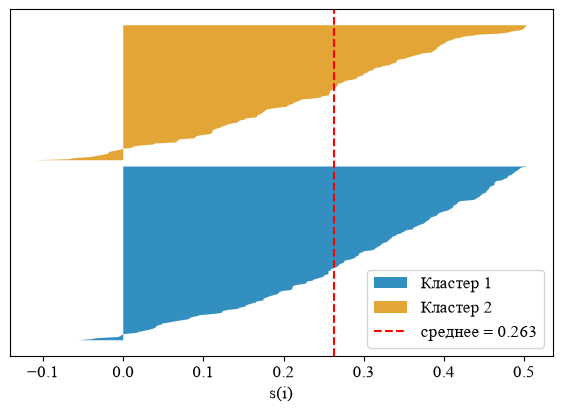

,К1,К2
age,52.1,57.6
sex,муж. (59 %),муж. (78 %)
cp,неангинозная боль (43 %),бессимптомно (82 %)
trestbps,129.4,134.6
chol,241.0,255.6
fbs,нет (86 %),нет (85 %)
restecg,норма (63 %),гипертрофия ЛЖ (66 %)
thalach,159.8,136.5
exang,нет (93 %),да (65 %)
oldpeak,0.6,1.7


In [21]:
def pam_profiles(df, G_mat, solution):
    """Пункт 6.3: силуэтная диаграмма, медоиды и профили кластеров PAM (средние и моды с долями)."""
    lab_pam, med_pam, cost_pam = solution
    k = len(med_pam)
    sil_s = metrics.silhouette_samples(G_mat, lab_pam, metric="precomputed")
    fig, ax = plt.subplots(figsize=(7, 4.5))
    y0 = 0
    for g in range(k):
        v = np.sort(sil_s[lab_pam == g])
        ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=0.8, label=f"Кластер {g + 1}")
        y0 += len(v) + 5
    ax.axvline(sil_s.mean(), color="red", ls="--", label=f"среднее = {sil_s.mean():.3f}")
    ax.set_xlabel("s(i)")
    ax.set_yticks([])
    ax.legend()
    savefig("fig_pam_silhouette")

    med_tab = df.loc[med_pam, FEATURES].T.astype(object)
    med_tab.columns = [f"Медоид К{g + 1}" for g in range(k)]
    for c in CATEGORICAL:
        med_tab.loc[c] = [CODES[c][int(v)] for v in med_tab.loc[c]]
    prof_rows = {}
    for g in range(k):
        sub = df[lab_pam == g]
        col = {}
        for c in FEATURES:
            if c in NUMERIC:
                col[c] = f"{sub[c].mean():.1f}"
            else:
                m = sub[c].value_counts(normalize=True)
                col[c] = f"{CODES[c][int(m.index[0])]} ({100 * m.iloc[0]:.0f} %)"
        col["N"] = len(sub)
        col["Доля болезни, %"] = f"{100 * sub.target.mean():.1f}"
        prof_rows[f"К{g + 1}"] = col
    pam_prof = pd.DataFrame(prof_rows)
    pam_prof.to_csv(RES / "pam_profile.csv")
    med_tab.to_csv(RES / "pam_medoids.csv")
    return pam_prof

lab_pam, med_pam, cost_pam = pam_sol[K_PAM]
pam_prof = pam_profiles(df, G_mat, pam_sol[K_PAM])
show(pam_prof)

**Функции и классы ячейки:**
- `pam_profiles` — пункт 6.3: силуэтная диаграмма, медоиды и профили кластеров PAM (средние и моды с долями).

**Что делает ячейка.** Для выбранного $k$ строит силуэтную диаграмму (значения $s(i)$ по объектам каждого кластера) и профили кластеров: для количественных признаков — средние, для категориальных — мода и её доля. Медоиды — типичные пациенты каждого кластера.

**Интерпретация кластеров Гауэр + PAM:**
- **К1 (167 чел., 20 % больных) — «низкий риск»:** моложе (52 года), высокая максимальная ЧСС (160), нет стенокардии нагрузки (93 %), восходящий сегмент ST (71 %), минимальная депрессия ST (0,6 мм), нормальный таллиевый тест (80 %), чаще неангинозная или атипичная боль; больше женщин (41 %);
- **К2 (130 чел., 80 % больных) — «ишемический профиль»:** старше (57,6 года), бессимптомная боль (82 %), стенокардия нагрузки (65 %), низкая ЧСС (136), плоский ST (74 %), депрессия ST 1,7 мм, обратимый дефект перфузии (65 %), гипертрофия ЛЖ на ЭКГ (66 %), преимущественно мужчины (78 %).

Силуэт 0,26 — структура умеренная (есть «пограничные» пациенты с $s(i)<0$), но разделение клинически осмысленно: кластеры совпадают с диагнозом для 80 % пациентов (Purity = 0,80), хотя диагноз в кластеризации не использовался.

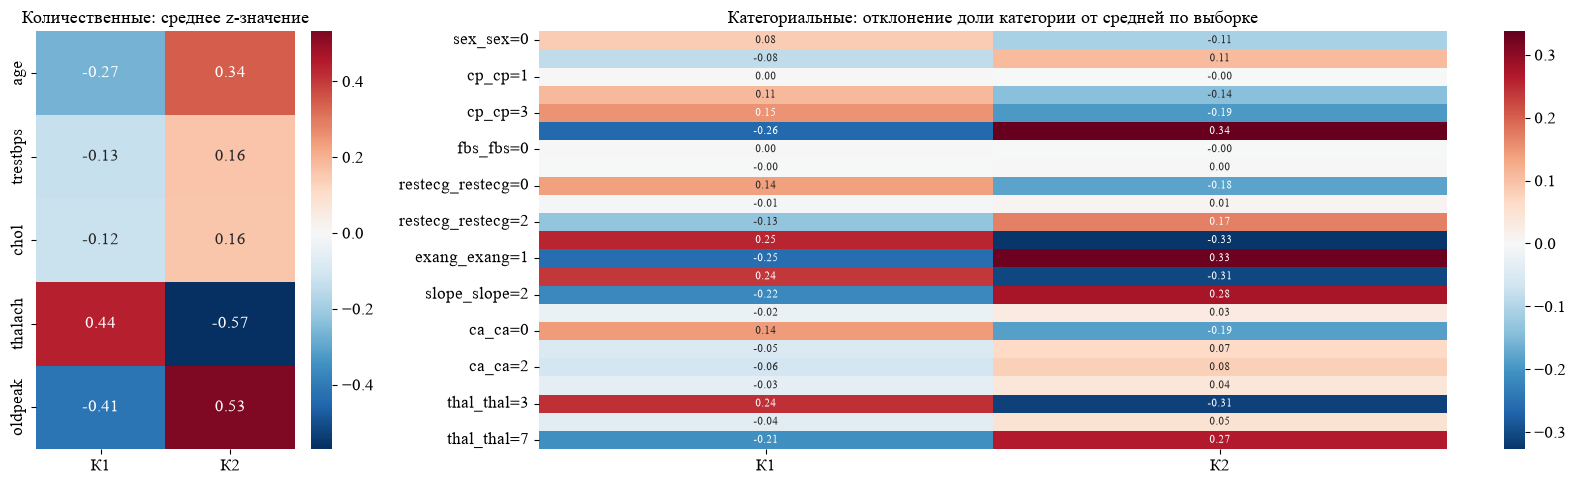

ARI                     0.3611
NMI                     0.2786
Homogeneity             0.2777
Completeness            0.2796
V-measure               0.2786
Purity                  0.8013
Silhouette (Хэмминг)    0.2014
Silhouette (Гауэр)      0.2628
dtype: float64

Диагноз,болезнь,нет болезни
Кластер PAM,,
1,33,134
2,104,26


In [22]:
def standardize(df):
    """z-преобразование количественных признаков: z = (x - mean) / std."""
    return (df[NUMERIC] - df[NUMERIC].mean()) / df[NUMERIC].std()


def pam_heatmaps(df, cat_all, lab_pam):
    """Тепловые карты профилей PAM: средние z-значения и отклонения долей категорий от средних по выборке."""
    z = standardize(df)
    num_prof = z.groupby(lab_pam).mean()
    num_prof.index = [f"К{k + 1}" for k in num_prof.index]
    dummies = pd.get_dummies(cat_all[CATEGORICAL].apply(lambda s: s.name + "=" + s))
    cat_prof = dummies.groupby(lab_pam).mean() - dummies.mean()
    cat_prof.index = num_prof.index
    fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 3.5]})
    sns.heatmap(num_prof.T, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0])
    axes[0].set_title("Количественные: среднее z-значение")
    sns.heatmap(cat_prof.T, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1], annot_kws={"size": 8})
    axes[1].set_title("Категориальные: отклонение доли категории от средней по выборке")
    plt.tight_layout()
    savefig("fig_pam_profile")

pam_heatmaps(df, cat_all, lab_pam)
m_pam = evaluate_solution(lab_pam, y, H_mat, G_mat)
ct_pam = diagnosis_crosstab(lab_pam, df, "Кластер PAM")
show(pd.Series(m_pam), 4)
show(ct_pam)

**Функции и классы ячейки:**
- `standardize` — z-преобразование количественных признаков: z = (x - mean) / std.
- `pam_heatmaps` — тепловые карты профилей PAM: средние z-значения и отклонения долей категорий от средних по выборке.

**Что делает ячейка.** Тепловые карты профилей кластеров PAM: для количественных признаков — средние стандартизованные значения $z=(x-\bar x)/s$, для категориальных — разность доли категории в кластере и в выборке (положительные значения — категория характерна для кластера). Затем считаются те же метрики качества, что и для CLOPE, и кросс-таблица «кластер × диагноз».

In [23]:
def clope_best_of(transactions, r, n_orders=50, **kwargs):
    """Запускает CLOPE для n_orders случайных порядков и возвращает решение с максимальным Profit.

    Результат — словарь с ключами labels, profit, history, n_iter, seed и profits.
    """
    best, profits = None, []
    for seed in range(n_orders):
        labels, p, hist, it = clope(transactions, r=r, seed=seed, **kwargs)
        profits.append(p)
        if best is None or p > best["profit"]:
            best = {"labels": labels, "profit": p, "history": hist, "n_iter": it, "seed": seed}
    best["profits"] = profits
    return best


def bootstrap_stability(transactions, G_mat, lab_clope, lab_pam, r_star, k_pam, n_rep=20, share=0.8):
    """Устойчивость к составу выборки: n_rep подвыборок по 80 %, ARI с исходным разбиением тех же объектов."""
    n = len(transactions)
    boot_p = []
    for s in range(n_rep):
        idx = np.sort(np.random.default_rng(s).choice(n, int(share * n), replace=False))
        lab_sub = pam(G_mat[np.ix_(idx, idx)], k_pam)[0]
        boot_p.append(metrics.adjusted_rand_score(lab_pam[idx], lab_sub))
    boot_c = []
    for s in range(n_rep):
        idx = np.sort(np.random.default_rng(s).choice(n, int(share * n), replace=False))
        tr_sub = [transactions[i] for i in idx]
        lab_sub = clope_best_of(tr_sub, r_star, n_orders=10)["labels"]
        lab_sub = merge_small_clusters(tr_sub, lab_sub, r_star, MIN_SHARE)
        boot_c.append(metrics.adjusted_rand_score(lab_clope[idx], lab_sub))
    tab = pd.DataFrame({"CLOPE": [np.mean(boot_c), np.std(boot_c)],
                        "Гауэр + PAM": [np.mean(boot_p), np.std(boot_p)]},
                       index=["ARI среднее", "ARI ст. откл."])
    tab.round(3).to_csv(RES / "bootstrap.csv")
    SUMMARY["boot"] = tab.to_dict()
    return tab

boot_tab = bootstrap_stability(transactions, G_mat, lab_clope, lab_pam, R_STAR, K_PAM)
show(boot_tab, 3)

,CLOPE,Гауэр + PAM
ARI среднее,0.220,0.986
ARI ст. откл.,0.123,0.030


**Функции и классы ячейки:**
- `clope_best_of` — запускает CLOPE для n_orders случайных порядков и возвращает решение с максимальным Profit.
- `bootstrap_stability` — устойчивость к составу выборки: n_rep подвыборок по 80 %, ARI с исходным разбиением тех же объектов.

**Что делает ячейка.** Проверяет устойчивость обоих решений к составу выборки: 20 раз случайно берутся 80 % пациентов, кластеризация повторяется, и разбиение подвыборки сравнивается (ARI) с исходным разбиением этих же пациентов. Чем ближе ARI к 1, тем стабильнее кластерная структура. (Для CLOPE используется тот же $r^*$, 10 порядков, объединение мелких кластеров.)

**Результат.** Решение PAM практически не меняется (ARI ≈ 0,99), решение CLOPE неустойчиво (ARI ≈ 0,22): при небольшом изменении выборки кластеры CLOPE перестраиваются.

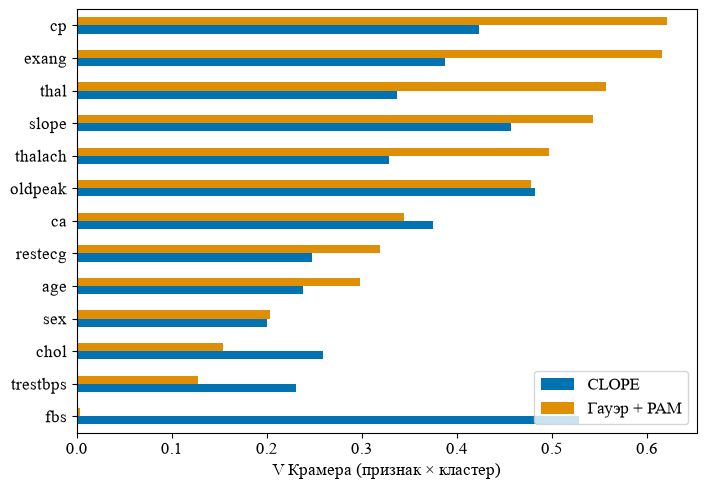

,feature,chi2,p_chi2,V,H,p_H,eta2,description
0,cp,114.6341,0.0000,0.6213,NaN,NaN,NaN,Тип боли в груди
1,exang,112.5759,0.0000,0.6157,NaN,NaN,NaN,"Стенокардия, вызванная нагрузкой"
2,thal,92.1192,0.0000,0.5569,NaN,NaN,NaN,Таллиевый стресс-тест
3,slope,87.7133,0.0000,0.5434,NaN,NaN,NaN,Наклон сегмента ST на пике нагрузки
4,thalach,73.2622,0.0000,0.4967,84.8892,0.0000,0.2844,"Максимальная ЧСС при нагрузке, уд/мин"
5,oldpeak,67.7889,0.0000,0.4778,71.2550,0.0000,0.2382,"Депрессия сегмента ST при нагрузке, мм"
6,ca,35.2821,0.0000,0.3447,NaN,NaN,NaN,"Число сосудов, окрашенных при флюороскопии"
7,restecg,30.2314,0.0000,0.3190,NaN,NaN,NaN,ЭКГ в покое
8,age,26.4254,0.0000,0.2983,29.1696,0.0000,0.0955,"Возраст, лет"
9,sex,12.2928,0.0005,0.2034,NaN,NaN,NaN,Пол


In [24]:
def pam_significance(cat_all, df, lab_pam, sig_clope):
    """Пункт 6.5: значимость признаков для PAM и сравнительная диаграмма V Крамера для обоих методов."""
    sig = feature_significance(cat_all, df[NUMERIC], lab_pam, DESCRIPTION)
    sig.round(4).to_csv(RES / "pam_significance.csv", index=False)
    both = sig_clope[["feature", "V"]].rename(columns={"V": "CLOPE"}).merge(
        sig[["feature", "V"]].rename(columns={"V": "Гауэр + PAM"}), on="feature").sort_values("Гауэр + PAM")
    fig, ax = plt.subplots(figsize=(8, 5.5))
    both.set_index("feature").plot(kind="barh", ax=ax)
    ax.set_xlabel("V Крамера (признак × кластер)")
    ax.set_ylabel("")
    savefig("fig_sig_compare")
    return sig

sig_pam = pam_significance(cat_all, df, lab_pam, sig_clope)
SUMMARY["pam"] = {"k": K_PAM, "sizes": np.bincount(lab_pam).tolist(), "cost": cost_pam,
                  "medoids": [int(m) for m in med_pam], "metrics": m_pam, "ct": ct_pam.to_dict("index")}
show(sig_pam, 4)

**Функции и классы ячейки:**
- `pam_significance` — пункт 6.5: значимость признаков для PAM и сравнительная диаграмма V Крамера для обоих методов.

**Что делает ячейка.** Оценивает значимость признаков для разбиения PAM теми же критериями ($\chi^2$, V Крамера, Краскел–Уоллис, $\eta^2_H$) и строит общий график значимости признаков для обоих методов.

### 6.3. Дополнительно: k-prototypes

In [25]:
def kprototypes_check(df, k, y, H_mat, G_mat, lab_pam):
    """Контрольное разбиение k-prototypes (Huang): z-значения количественных и коды категориальных признаков."""
    Xkp = pd.concat([standardize(df), df[CATEGORICAL].astype(str)], axis=1).to_numpy(dtype=object)
    cat_idx = list(range(len(NUMERIC), len(NUMERIC) + len(CATEGORICAL)))
    kp = KPrototypes(n_clusters=k, init="Cao", n_init=10, random_state=0)
    lab_kp = kp.fit_predict(Xkp, categorical=cat_idx)
    m_kp = evaluate_solution(lab_kp, y, H_mat, G_mat)
    ari_pam = metrics.adjusted_rand_score(lab_pam, lab_kp)
    SUMMARY["kproto"] = {"k": k, "gamma": float(kp.gamma), "sizes": np.bincount(lab_kp).tolist(),
                         "metrics": m_kp, "ari_pam": ari_pam}
    print("gamma =", round(kp.gamma, 3), " размеры:", np.bincount(lab_kp).tolist())
    print("ARI(k-prototypes, PAM) =", round(ari_pam, 4))
    return lab_kp, m_kp

lab_kp, m_kp = kprototypes_check(df, K_PAM, y, H_mat, G_mat, lab_pam)
show(pd.Series(m_kp), 4)

gamma = 0.499  размеры: [162, 135]
ARI(k-prototypes, PAM) = 0.3775


ARI                     0.2228
NMI                     0.1669
Homogeneity             0.1668
Completeness            0.1671
V-measure               0.1669
Purity                  0.7374
Silhouette (Хэмминг)    0.1663
Silhouette (Гауэр)      0.1805
dtype: float64

**Функции и классы ячейки:**
- `kprototypes_check` — контрольное разбиение k-prototypes (Huang): z-значения количественных и коды категориальных признаков.

**Что делает ячейка.** Для контроля строит разбиение алгоритмом k-prototypes (Huang, 1998) с тем же числом кластеров. Количественные признаки стандартизуются, категориальные сравниваются по совпадению:

$$E=\sum_{l=1}^{k}\sum_{i\in C_l}\left[\sum_{j\in num}(x_{ij}-q_{lj})^2+\gamma\sum_{j\in cat}\delta(x_{ij},q_{lj})\right],$$

$q_l$ — прототип кластера (средние по количественным признакам и моды по категориальным), $\gamma$ — вес категориальной части (по умолчанию половина среднего стандартного отклонения количественных признаков). Близость решения k-prototypes к PAM показывает, что найденная структура не артефакт одного алгоритма.

**Результат.** k-prototypes находит похожую структуру из двух групп (ARI с PAM ≈ 0,38), но согласие с диагнозом ниже (ARI = 0,22 против 0,36): квадрат евклидова расстояния сильнее реагирует на выбросы количественных признаков (`chol`, `oldpeak`), а мера Гауэра с нормировкой размахом и медоидами устойчивее.

## 7. Сравнение решений

In [26]:
def compare_solutions(m_clope, m_pam, m_kp, k_clope, k_pam, lab_clope, lab_pam):
    """Пункт 7: сводная таблица метрик методов и кросс-таблица «кластер CLOPE × кластер PAM»."""
    cmp = pd.DataFrame({"CLOPE": m_clope, "Гауэр + PAM": m_pam, "k-prototypes": m_kp}).T
    cmp.insert(0, "k", [k_clope, k_pam, k_pam])
    cmp.round(4).to_csv(RES / "compare.csv")
    ct_cp = pd.crosstab(pd.Series(lab_clope + 1, name="CLOPE"), pd.Series(lab_pam + 1, name="PAM"))
    ct_cp.to_csv(RES / "crosstab_clope_pam.csv")
    SUMMARY["compare"] = {"ari_clope_pam": metrics.adjusted_rand_score(lab_clope, lab_pam),
                          "nmi_clope_pam": metrics.normalized_mutual_info_score(lab_clope, lab_pam),
                          "ct": ct_cp.to_dict("index")}
    print("ARI(CLOPE, PAM) =", round(SUMMARY["compare"]["ari_clope_pam"], 4),
          " NMI(CLOPE, PAM) =", round(SUMMARY["compare"]["nmi_clope_pam"], 4))
    return cmp, ct_cp

cmp, ct_cp = compare_solutions(m_clope, m_pam, m_kp, K_CLOPE, K_PAM, lab_clope, lab_pam)
show(ct_cp)
show(cmp, 4)

ARI(CLOPE, PAM) = 0.102  NMI(CLOPE, PAM) = 0.1055


PAM,1,2
CLOPE,,
1,117,54
2,6,33
3,18,7
4,3,19
5,8,12
6,15,5


,k,ARI,NMI,Homogeneity,Completeness,V-measure,Purity,Silhouette (Хэмминг),Silhouette (Гауэр)
CLOPE,6,0.0764,0.0896,0.1323,0.0677,0.0896,0.6970,0.0128,0.0154
Гауэр + PAM,2,0.3611,0.2786,0.2777,0.2796,0.2786,0.8013,0.2014,0.2628
k-prototypes,2,0.2228,0.1669,0.1668,0.1671,0.1669,0.7374,0.1663,0.1805


**Функции и классы ячейки:**
- `compare_solutions` — пункт 7: сводная таблица метрик методов и кросс-таблица «кластер CLOPE × кластер PAM».

**Что делает ячейка.** Сводит метрики всех решений в одну таблицу и строит кросс-таблицу «кластер CLOPE × кластер PAM», а также ARI/NMI между двумя разбиениями (насколько методы находят одинаковую структуру).

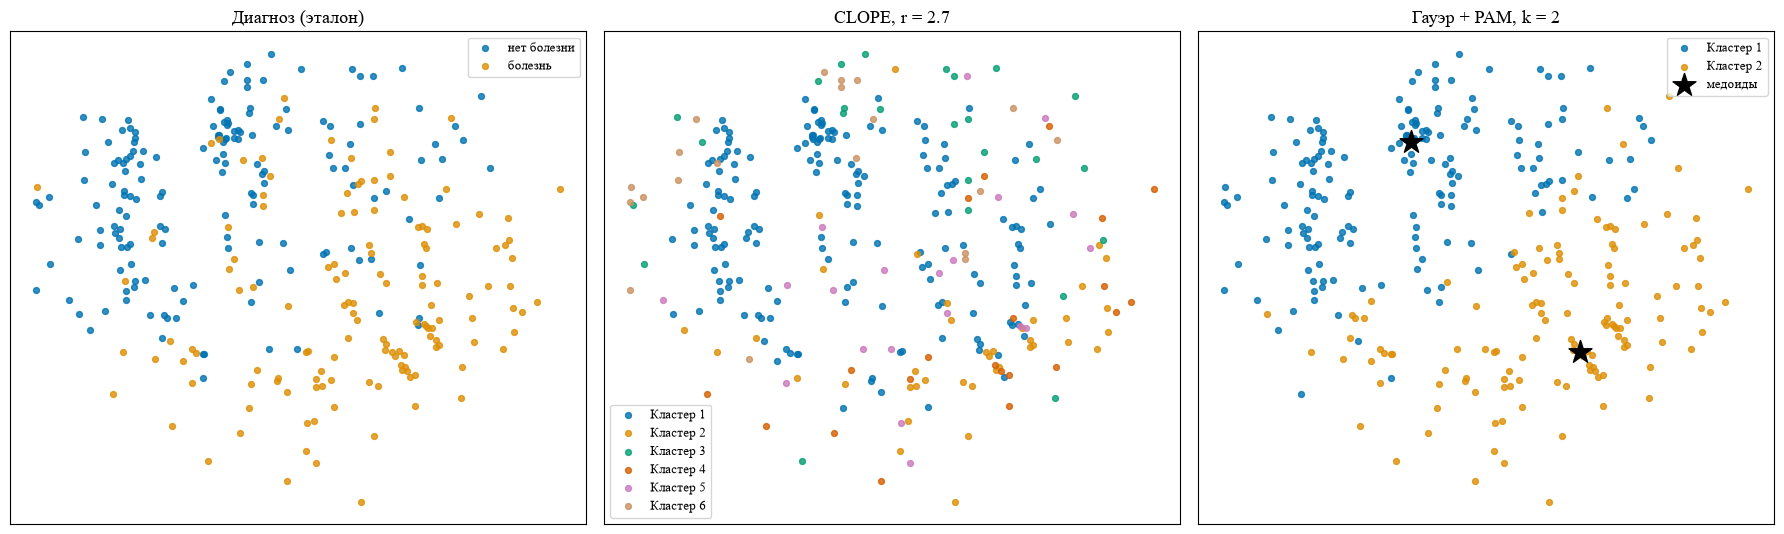

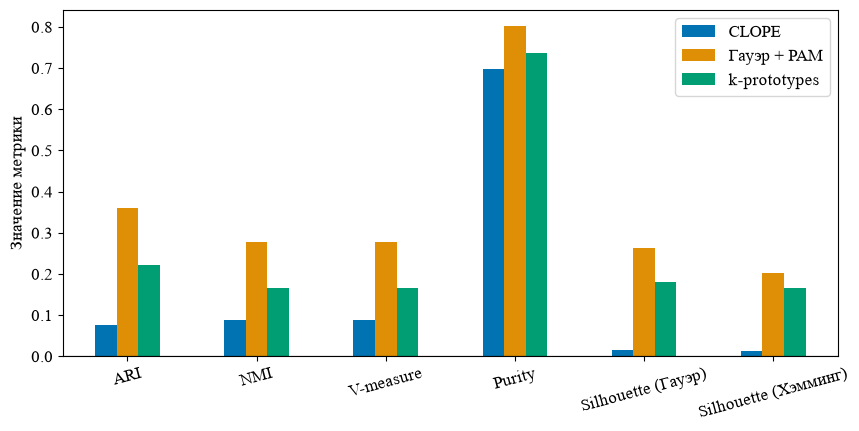

In [27]:
def mds_embedding(G_mat):
    """Двумерная проекция объектов методом MDS по матрице расстояний Гауэра."""
    try:
        mds = MDS(n_components=2, metric="precomputed", random_state=0, n_init=4, init="random")
        return mds.fit_transform(G_mat)
    except TypeError:
        mds = MDS(n_components=2, dissimilarity="precomputed", random_state=0, n_init=4)
        return mds.fit_transform(G_mat)


def plot_comparison(G_mat, y, lab_clope, lab_pam, med_pam, r_star, k_pam, cmp):
    """Проекция MDS с раскраской по диагнозу, CLOPE и PAM и столбчатая диаграмма метрик методов."""
    emb = mds_embedding(G_mat)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    panels = [("Диагноз (эталон)", y), (f"CLOPE, r = {r_star}", lab_clope), (f"Гауэр + PAM, k = {k_pam}", lab_pam)]
    for ax, (title, lab) in zip(axes, panels):
        for g in np.unique(lab):
            name = CODES["target"][g] if title.startswith("Диагноз") else f"Кластер {g + 1}"
            ax.scatter(emb[lab == g, 0], emb[lab == g, 1], s=18, alpha=0.8, label=name)
        ax.set_title(title)
        ax.legend(fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[2].scatter(emb[med_pam, 0], emb[med_pam, 1], marker="*", s=300, c="black", label="медоиды")
    axes[2].legend(fontsize=9)
    plt.tight_layout()
    savefig("fig_mds")

    fig, ax = plt.subplots(figsize=(10, 4.5))
    cmp[["ARI", "NMI", "V-measure", "Purity", "Silhouette (Гауэр)", "Silhouette (Хэмминг)"]].T.plot(kind="bar", ax=ax, rot=15)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylabel("Значение метрики")
    savefig("fig_compare")

plot_comparison(G_mat, y, lab_clope, lab_pam, med_pam, R_STAR, K_PAM, cmp)

**Функции и классы ячейки:**
- `mds_embedding` — двумерная проекция объектов методом MDS по матрице расстояний Гауэра.
- `plot_comparison` — проекция MDS с раскраской по диагнозу, CLOPE и PAM и столбчатая диаграмма метрик методов.

**Что делает ячейка.** Проецирует пациентов на плоскость методом многомерного шкалирования (MDS) по матрице Гауэра — точки располагаются так, чтобы евклидовы расстояния на плоскости как можно лучше воспроизводили $d_G$ (минимизация stress $\sum_{i<j}(\|z_i-z_j\|-d_{ij})^2$). Раскраска: диагноз, кластеры CLOPE, кластеры PAM (звёзды — медоиды). Вторая диаграмма — сравнение метрик методов.

**Выводы сравнения.**
1. По всем метрикам решение Гауэр + PAM лучше: силуэт 0,26 против 0,01–0,02, ARI с диагнозом 0,36 против 0,08, Purity 0,80 против 0,70, устойчивость 0,99 против 0,22.
2. Решения согласуются слабо (ARI = 0,10): кластеры CLOPE К2 и К4 почти целиком входят в «ишемический» кластер PAM К2, К6 и К3 — в «низкорисковый» К1, а большой кластер К1 CLOPE делится между обоими кластерами PAM (117 / 54).
3. Причина различий — в природе методов: CLOPE оптимизирует «перекрытие» наборов элементов и чувствителен к редким элементам и к порядку данных; он эффективен для разреженных транзакционных данных с разными наборами элементов (демо-пример с грибами — ни одного «грязного» кластера). Мера Гауэра использует количественную информацию без потерь на дискретизацию и сравнивает пациентов по всем признакам одновременно, поэтому лучше подходит для «плотных» смешанных данных, где группы различаются частотами и величинами, а не наличием элементов.

In [28]:
def to_py(o):
    """Рекурсивно приводит типы NumPy к встроенным типам Python для записи в JSON."""
    if isinstance(o, dict):
        return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_py(v) for v in o]
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    return o


def save_results(lab_clope, lab_raw, lab_pam, lab_kp, y):
    """Сохраняет метки кластеров всех методов (results/labels.csv) и сводку ключевых чисел (results/summary.json)."""
    pd.DataFrame({"clope": lab_clope + 1, "clope_raw": lab_raw + 1, "pam": lab_pam + 1, "kproto": lab_kp + 1,
                  "target": y}).to_csv(RES / "labels.csv", index=False)
    (RES / "summary.json").write_text(json.dumps(to_py(SUMMARY), ensure_ascii=False, indent=1))
    print("Сохранено:", sorted(p.name for p in RES.iterdir()))

save_results(lab_clope, lab_raw, lab_pam, lab_kp, y)

Сохранено: ['assoc_target.csv', 'bootstrap.csv', 'clope_char.csv', 'clope_clusters.csv', 'clope_clusters_raw.csv', 'clope_grid.csv', 'clope_significance.csv', 'compare.csv', 'crosstab_clope_pam.csv', 'demo_mushroom.csv', 'desc_numeric.csv', 'discretization.csv', 'features.csv', 'freq_categorical.csv', 'gower_example.csv', 'labels.csv', 'long_fragment.csv', 'pam_grid.csv', 'pam_medoids.csv', 'pam_profile.csv', 'pam_significance.csv', 'summary.json']


**Функции и классы ячейки:**
- `to_py` — рекурсивно приводит типы NumPy к встроенным типам Python для записи в JSON.
- `save_results` — сохраняет метки кластеров всех методов (results/labels.csv) и сводку ключевых чисел (results/summary.json).

**Что делает ячейка.** Сохраняет метки кластеров всех методов (`results/labels.csv`) и сводку ключевых чисел (`results/summary.json`), по которым составлен отчёт.

## 8. Теоретический конспект к защите

### 8.1. Методы кластеризации категориальных и смешанных данных
- **Разбиение (partitioning):** k-modes (категориальные), k-prototypes (смешанные), PAM / CLARA с произвольной мерой (Гауэр, Хэмминг, Журавлёв).
- **Иерархические:** агломеративная кластеризация по матрице Гауэра/Хэмминга/Жаккара; ROCK (связи через общих соседей).
- **Транзакционные / по глобальному критерию:** CLOPE, LargeItem, COOLCAT (энтропия).
- **Через преобразование признаков:** one-hot кодирование + k-means; FAMD / MCA (факторный анализ смешанных данных) + k-means в пространстве факторов.
- **Модельные:** латентный классовый анализ (смеси мультиномиальных распределений).

### 8.2. k-modes (Huang, 1998)
Расстояние — простое несовпадение (Хэмминг): $d(x,y)=\sum_{j=1}^{p}\delta(x_j,y_j)$, $\delta=0$ при $x_j=y_j$, иначе 1. Центр кластера — **мода** $Q_l$ (наиболее частая категория каждого признака). Минимизируется
$$E=\sum_{l=1}^{k}\sum_{i\in C_l} d(x_i,Q_l).$$
Алгоритм: выбор $k$ начальных мод (случайно, Huang или Cao) → отнесение объектов к ближайшей моде → пересчёт мод → повтор до стабилизации.

### 8.3. k-prototypes (Huang, 1997)
Объединяет k-means и k-modes:
$$d(x_i,q_l)=\sum_{j\in num}(x_{ij}-q_{lj})^2+\gamma\sum_{j\in cat}\delta(x_{ij},q_{lj}),$$
прототип = средние по количественным + моды по категориальным признакам; $\gamma$ балансирует вклад частей (обычно порядка стандартного отклонения количественных признаков).

### 8.4. CLOPE (Yang, Guan, You, 2002)
Кластер описывается гистограммой элементов: $S$ — площадь, $W$ — ширина, $H=S/W$ — высота. Качество кластера — градиент $G=S/W^r$. Критерий
$$Profit_r=\frac{\sum_i \frac{S_i}{W_i^r}N_i}{\sum_i N_i}\to\max,$$
$r$ — коэффициент отталкивания (чем больше, тем более схожими должны быть транзакции кластера и тем больше кластеров). Алгоритм: 1) первый проход — каждая транзакция в кластер с максимальным $\Delta Add$ (или в новый); 2) повторные проходы — перемещение транзакций, пока есть перемещения (Profit растёт). Достоинства: число кластеров не задаётся, нет матрицы расстояний, сложность $O(N\cdot K\cdot A)$ на проход, несколько проходов по данным — подходит для больших БД. Недостатки: эвристика, зависит от порядка транзакций; для плотных данных (все объекты описаны всеми признаками) склонна к вырожденным решениям.

### 8.5. Меры расстояния
- **Хэмминг:** $d_H(x,y)=\sum_j[x_j\neq y_j]$ (или доля несовпадений $\frac1p\sum_j[x_j\neq y_j]$).
- **Жаккар** (для множеств/транзакций): $d_J(A,B)=1-\dfrac{|A\cap B|}{|A\cup B|}$.
- **Гауэр:** $d_G(i,j)=\dfrac{\sum_f w_{ijf}\delta_{ijf}}{\sum_f w_{ijf}}$, где $\delta_{ijf}=|x_{if}-x_{jf}|/R_f$ для количественных, $[x_{if}\neq x_{jf}]$ для номинальных; для порядковых — ранги, нормированные размахом; $w_{ijf}=0$ при пропуске; для асимметричных бинарных признаков совпадение «0–0» не учитывается.
- **Мера Журавлёва** (функция близости для разнотипных признаков): объекты считаются близкими по признаку $j$, если $|x_{ij}-x_{kj}|\le\varepsilon_j$ (количественный, $\varepsilon_j$ — порог) или $x_{ij}=x_{kj}$ (категориальный):
$$\mu(x_i,x_k)=\sum_{j=1}^{p}\left[\,|x_{ij}-x_{kj}|\le\varepsilon_j\,\right],\qquad d(x_i,x_k)=p-\mu(x_i,x_k).$$
Мера равна числу признаков, по которым объекты «совпадают» с точностью до порога; для категориальных признаков ($\varepsilon_j=0$) расстояние $p-\mu$ совпадает с расстоянием Хэмминга.